# Memory Fault Injection — Resilience Analysis
**Model:** Fashion-MNIST Image Classification (INT8 quantized TFLite)  
**Target:** Model memory (weights and biases — transient bit-flip)  
**Campaign:** `memoryfi_image_classification`  
**Sampling:** Stratified per operator — 95% confidence, 5% margin

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from scipy import stats
import json

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "figure.figsize": (10, 5)})

RUN_DIR = Path(".")  # notebook lives inside the run directory

SEVERITY_ORDER = ["Masked", "Good", "Acceptable", "Warning", "Critical", "Crash"]
SEVERITY_COLORS = {
    "Masked": "#4CAF50",
    "Good": "#81C784",
    "Acceptable": "#FFC107",
    "Warning": "#FF9800",
    "Critical": "#F44336",
    "Crash": "#B71C1C",
}

CRITICAL_SET = {"Critical", "Crash"}
DEGRADED_SET = {"Warning", "Critical", "Crash"}

## 1. Data Loading

In [4]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from scipy import stats

# Constants (re-declared so this cell runs standalone)
SEVERITY_ORDER = ["Masked", "Good", "Acceptable", "Warning", "Critical", "Crash"]
SEVERITY_COLORS = {
    "Masked": "#4CAF50", "Good": "#81C784", "Acceptable": "#FFC107",
    "Warning": "#FF9800", "Critical": "#F44336", "Crash": "#B71C1C",
}
CRITICAL_SET = {"Critical", "Crash"}
DEGRADED_SET = {"Warning", "Critical", "Crash"}

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "figure.figsize": (10, 5)})

RUN_DIR = Path.cwd()
if not (RUN_DIR / "classified_results.csv").exists():
    RUN_DIR = Path(r"c:\Downloads\framework_jose\analysis_runs\Memória_LeNet-5_transient")
print(f"RUN_DIR = {RUN_DIR}")

df          = pd.read_csv(RUN_DIR / "classified_results.csv")
sel         = pd.read_csv(RUN_DIR / "selected_faults.csv")
sel_by_layer = pd.read_csv(RUN_DIR / "selected_faults_by_layer.csv")
pop_by_op   = pd.read_csv(RUN_DIR / "population_by_operator.csv")
tensor_map  = pd.read_csv(RUN_DIR / "tensor_map.csv")

with open(RUN_DIR / "run_manifest.json") as f:
    manifest = json.load(f)

# Merge metadados por fault_id
fault_meta = sel[["fault_id", "tensor_index", "tensor_name", "byte_in_tensor",
                  "global_byte_offset", "bit_index"]].drop_duplicates("fault_id")
df = df.merge(fault_meta, on="fault_id", how="left", suffixes=("", "_sel"))
if "tensor_name" in df.columns and "tensor_name_sel" in df.columns:
    df["tensor_name"] = df["tensor_name"].fillna(df["tensor_name_sel"])

# --- Rotulagem correta de tensor -----------------------------------------
# Cada linha do tensor_map corresponde a um tensor_index distinto no flatbuffer.
# Usamos o ramo final do nome fundido (após ';') e ficamos com os 2 últimos
# segmentos do path, produzindo rótulos únicos tipo 'conv2d_3_1/Squeeze'.
def short_tensor_label(name: str) -> str:
    last_branch = str(name).split(";")[-1]
    parts = last_branch.split("/")
    return "/".join(parts[-2:]) if len(parts) >= 2 else last_branch

tensor_map["tensor_label"] = tensor_map["name"].apply(short_tensor_label)
tensor_map["tensor_type"]  = tensor_map["name"].apply(
    lambda s: "bias" if ("Bias" in s or "bias" in s) else "weight"
)

# Verificação: labels devem ser únicos por tensor_index
dup = tensor_map["tensor_label"].duplicated().sum()
assert dup == 0, f"Colisão de tensor_label detectada ({dup} duplicatas)"

label_map = tensor_map.set_index("tensor_index")["tensor_label"].to_dict()
type_map  = tensor_map.set_index("tensor_index")["tensor_type"].to_dict()
df["tensor_label"] = df["tensor_index"].map(label_map)
df["tensor_type"]  = df["tensor_index"].map(type_map).fillna("unknown")
# -------------------------------------------------------------------------

present_classes = [c for c in SEVERITY_ORDER if c in df["fault_class"].unique()]

print(f"Total classified results : {len(df):,}")
print(f"Unique faults injected   : {df['fault_id'].nunique():,}")
print(f"Images per fault         : {len(df) // max(df['fault_id'].nunique(), 1)}")
print(f"Operators targeted       : {df['operator_index'].nunique()}")
print(f"Tensors targeted         : {df['tensor_index'].nunique()}")
print(f"Unique tensor labels     : {df['tensor_label'].nunique()}")
print(f"Fault model              : {manifest.get('campaign_type', 'memory')}")
print(f"Fault duration           : {manifest.get('fault_duration', 'transient')}")
print(f"Severity classes present : {present_classes}")
df.head(3)

RUN_DIR = c:\Downloads\framework_jose\analysis_runs\Memória_LeNet-5_transient
Total classified results : 181,093
Unique faults injected   : 1,811
Images per fault         : 99
Operators targeted       : 5
Tensors targeted         : 10
Unique tensor labels     : 10
Fault model              : memory
Fault duration           : transient
Severity classes present : ['Masked', 'Good', 'Acceptable', 'Warning', 'Critical']


,event,mode,fault_id,image_id,label,pred_class,top1_prob,golden_pred_class,golden_top1_prob,operator_index,...,golden_pred_class_ref,golden_top1_prob_ref,fault_class,tensor_index_sel,tensor_name,byte_in_tensor_sel,global_byte_offset,bit_index_sel,tensor_label,tensor_type
0,result,fault,2,0,9,9,0.996094,9.0,0.996094,0.0,...,9,0.996094,Masked,13,le_net5_1_1/lenet5_1/conv1_1/convolution,0,576,2,conv1_1/convolution,weight
1,result,fault,2,1,7,7,0.996094,7.0,0.996094,0.0,...,7,0.996094,Masked,13,le_net5_1_1/lenet5_1/conv1_1/convolution,0,576,2,conv1_1/convolution,weight
2,result,fault,2,2,6,6,0.914062,6.0,0.914062,0.0,...,6,0.914062,Masked,13,le_net5_1_1/lenet5_1/conv1_1/convolution,0,576,2,conv1_1/convolution,weight


In [5]:
dt = pd.read_csv('classified_results.csv')

In [6]:
dt

,event,mode,fault_id,image_id,label,pred_class,top1_prob,golden_pred_class,golden_top1_prob,operator_index,tensor_index,byte_in_tensor,bit_index,status,golden_pred_class_ref,golden_top1_prob_ref,fault_class
0,result,fault,2,0,9,9,0.996094,9.0,0.996094,0.0,13.0,0.0,2.0,ok,9,0.996094,Masked
1,result,fault,2,1,7,7,0.996094,7.0,0.996094,0.0,13.0,0.0,2.0,ok,7,0.996094,Masked
2,result,fault,2,2,6,6,0.914062,6.0,0.914062,0.0,13.0,0.0,2.0,ok,6,0.914062,Masked
3,result,fault,2,3,2,2,0.996094,2.0,0.996094,0.0,13.0,0.0,2.0,ok,2,0.996094,Masked
4,result,fault,2,4,2,2,0.996094,2.0,0.996094,0.0,13.0,0.0,2.0,ok,2,0.996094,Masked
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
181088,result,fault,499296,95,7,7,0.617188,7.0,0.996094,10.0,4.0,38.0,0.0,ok,7,0.996094,Warning
181089,result,fault,499296,96,2,2,0.996094,2.0,0.996094,10.0,4.0,38.0,0.0,ok,2,0.996094,Masked
181090,result,fault,499296,97,3,9,0.988281,3.0,0.996094,10.0,4.0,38.0,0.0,ok,3,0.996094,Critical
181091,result,fault,499296,98,2,2,0.996094,2.0,0.996094,10.0,4.0,38.0,0.0,ok,2,0.996094,Masked


## 2. Overall Fault Classification Distribution

,Count,Percentage (%)
fault_class,,
Masked,176219.0,97.31
Good,7.0,0.00
Acceptable,2897.0,1.60
Warning,788.0,0.44
Critical,1182.0,0.65
TOTAL,181093.0,100.00


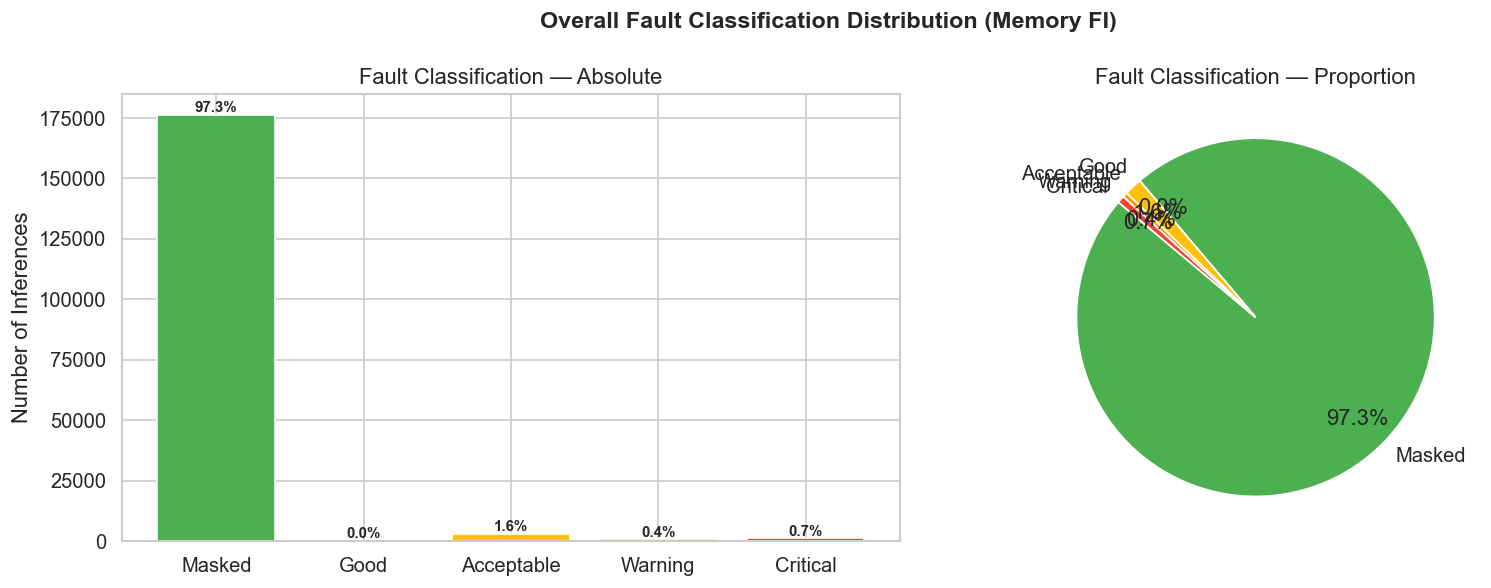

In [7]:
fc_counts = df["fault_class"].value_counts()
fc_ordered = fc_counts.reindex(SEVERITY_ORDER).dropna().astype(int)
fc_pct = fc_ordered / len(df) * 100

summary_table = pd.DataFrame({"Count": fc_ordered, "Percentage (%)": fc_pct.round(2)})
summary_table.loc["TOTAL"] = [len(df), 100.0]
display(summary_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
colors = [SEVERITY_COLORS.get(c, "#999") for c in fc_ordered.index]
bars = axes[0].bar(fc_ordered.index, fc_ordered.values, color=colors, edgecolor="white")
for bar, pct in zip(bars, fc_pct.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                 f"{pct:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylabel("Number of Inferences")
axes[0].set_title("Fault Classification — Absolute")

# Pie chart
axes[1].pie(fc_ordered.values, labels=fc_ordered.index, colors=colors,
            autopct="%1.1f%%", startangle=140, pctdistance=0.8)
axes[1].set_title("Fault Classification — Proportion")

fig.suptitle("Overall Fault Classification Distribution (Memory FI)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_overall_classification.png", bbox_inches="tight")
plt.show()

## 3. Resilience per Tensor
Each tensor in the TFLite model (weights and biases) is a distinct fault target. We evaluate how each tensor responds to transient bit-flips in its memory region.

fault_class,tensor_index,display_label,tensor_type,total,Masked,Acceptable,Warning,Critical,Crash,critical_rate,degraded_rate
plot_label,,,,,,,,,,,
conv2_1/BiasAdd [bias],10.0,conv2_1/BiasAdd,bias,700,443,37,21,199,0,0.2843,0.3143
conv1_1/BiasAdd [bias],12.0,conv1_1/BiasAdd,bias,3600,2413,282,243,661,0,0.1836,0.2511
fc2_1/BiasAdd [bias],4.0,fc2_1/BiasAdd,bias,1600,1249,39,29,282,0,0.1762,0.1944
fc1_1/BiasAdd [bias],6.0,fc1_1/BiasAdd,bias,1600,1346,139,85,25,0,0.0156,0.0688
conv3_1/BiasAdd [bias],8.0,conv3_1/BiasAdd,bias,393,354,25,8,6,0,0.0153,0.0356
conv1_1/convolution [weight],13.0,conv1_1/convolution,weight,26600,25303,1096,192,9,0,0.0003,0.0076
fc2_1/MatMul [weight],5.0,fc2_1/MatMul,weight,34900,34606,270,24,0,0,0.0000,0.0007
fc1_1/MatMul [weight],7.0,fc1_1/MatMul,weight,36700,36576,108,16,0,0,0.0000,0.0004
conv3_1/convolution [weight],9.0,conv3_1/convolution,weight,38000,37856,123,21,0,0,0.0000,0.0006


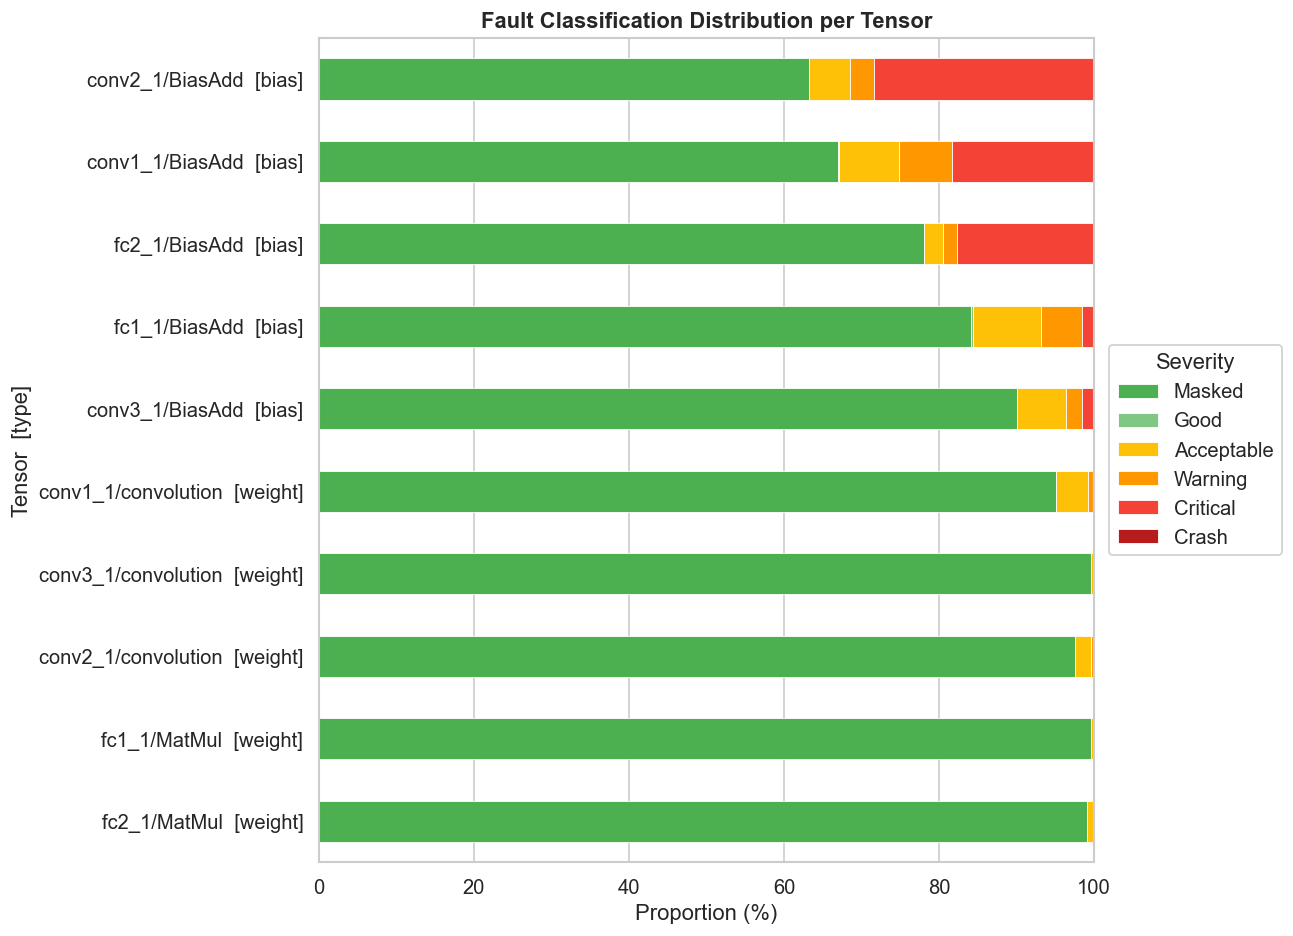

In [8]:
# --- Label de exibição semanticamente correto --------------------------------
# Para tensores fundidos (nome com ';'), prefere o ramo 'BiasAdd' quando presente,
# senão usa o último ramo. Mantém os 2 últimos segmentos do path.
def _display_label(name: str) -> str:
    branches = str(name).split(";")
    chosen = next((b for b in branches if "BiasAdd" in b), branches[-1])
    parts = chosen.split("/")
    return "/".join(parts[-2:]) if len(parts) >= 2 else chosen

# Mapa tensor_index -> display_label (usa o nome completo original em df["tensor_name"])
_name_by_idx = (
    df.dropna(subset=["tensor_name"])
      .drop_duplicates("tensor_index")
      .set_index("tensor_index")["tensor_name"]
)
display_label_map = {idx: _display_label(n) for idx, n in _name_by_idx.items()}

# Verificação de unicidade do label de exibição
assert len(set(display_label_map.values())) == len(display_label_map), (
    "Colisão de display_label detectada — ajuste _display_label()"
)

df["display_label"] = df["tensor_index"].map(display_label_map)
# ---------------------------------------------------------------------------

# Aggregate by tensor_index (chave física) — display_label apenas para exibição
tensor_fc = (
    df.groupby(["tensor_index", "display_label", "tensor_type"])["fault_class"]
      .value_counts().unstack(fill_value=0)
)
tensor_fc = tensor_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)
tensor_fc["total"]         = tensor_fc.sum(axis=1)
tensor_fc["critical_rate"] = (tensor_fc.get("Critical", 0) + tensor_fc.get("Crash", 0)) / tensor_fc["total"]
tensor_fc["degraded_rate"] = tensor_fc[[c for c in DEGRADED_SET if c in tensor_fc.columns]].sum(axis=1) / tensor_fc["total"]
tensor_fc = tensor_fc.sort_values("critical_rate", ascending=False)

# Índice achatado com display_label para plot (anota tipo para desambiguar visualmente)
tensor_fc_display = tensor_fc.reset_index()
tensor_fc_display["plot_label"] = (
    tensor_fc_display["display_label"] + "  [" + tensor_fc_display["tensor_type"] + "]"
)
tensor_fc_display = tensor_fc_display.set_index("plot_label")

display(tensor_fc_display[["tensor_index", "display_label", "tensor_type", "total",
                           "Masked", "Acceptable", "Warning", "Critical", "Crash",
                           "critical_rate", "degraded_rate"]].round(4))

# Stacked bar — percentage per tensor
tensor_pct = tensor_fc_display[SEVERITY_ORDER].div(tensor_fc_display["total"], axis=0) * 100
tensor_pct_sorted = tensor_pct.sort_values("Critical", ascending=True)

fig, ax = plt.subplots(figsize=(13, 8))
tensor_pct_sorted.plot.barh(
    stacked=True, ax=ax,
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white", linewidth=0.5,
)
ax.set_xlabel("Proportion (%)")
ax.set_ylabel("Tensor  [type]")
ax.set_title("Fault Classification Distribution per Tensor", fontweight="bold")
ax.set_xlim(0, 100)

# Legenda fora do eixo — sem colisão com barras
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    title="Severity",
    framealpha=0.95,
    borderaxespad=0.0,
)

plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.savefig(RUN_DIR / "fig_classification_per_tensor.png", bbox_inches="tight")
plt.show()

In [9]:
dt = pd.read_csv('classified_results.csv')

In [10]:
dt

,event,mode,fault_id,image_id,label,pred_class,top1_prob,golden_pred_class,golden_top1_prob,operator_index,tensor_index,byte_in_tensor,bit_index,status,golden_pred_class_ref,golden_top1_prob_ref,fault_class
0,result,fault,2,0,9,9,0.996094,9.0,0.996094,0.0,13.0,0.0,2.0,ok,9,0.996094,Masked
1,result,fault,2,1,7,7,0.996094,7.0,0.996094,0.0,13.0,0.0,2.0,ok,7,0.996094,Masked
2,result,fault,2,2,6,6,0.914062,6.0,0.914062,0.0,13.0,0.0,2.0,ok,6,0.914062,Masked
3,result,fault,2,3,2,2,0.996094,2.0,0.996094,0.0,13.0,0.0,2.0,ok,2,0.996094,Masked
4,result,fault,2,4,2,2,0.996094,2.0,0.996094,0.0,13.0,0.0,2.0,ok,2,0.996094,Masked
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
181088,result,fault,499296,95,7,7,0.617188,7.0,0.996094,10.0,4.0,38.0,0.0,ok,7,0.996094,Warning
181089,result,fault,499296,96,2,2,0.996094,2.0,0.996094,10.0,4.0,38.0,0.0,ok,2,0.996094,Masked
181090,result,fault,499296,97,3,9,0.988281,3.0,0.996094,10.0,4.0,38.0,0.0,ok,3,0.996094,Critical
181091,result,fault,499296,98,2,2,0.996094,2.0,0.996094,10.0,4.0,38.0,0.0,ok,2,0.996094,Masked


## 4. Resilience per Tensor Type (Bias vs Weight)
Tensors are grouped by their role: **bias** tensors (additive parameters) tend to be smaller but more sensitive, while **weight** tensors (multiplicative parameters) are larger but often more resilient per-byte.

fault_class,Masked,Good,Acceptable,Warning,Critical,Crash,total,critical_rate,degraded_rate
tensor_type,,,,,,,,,
bias,5805,7,522,386,1173,0,7893,0.1486,0.1975
weight,170414,0,2375,402,9,0,173200,0.0001,0.0024


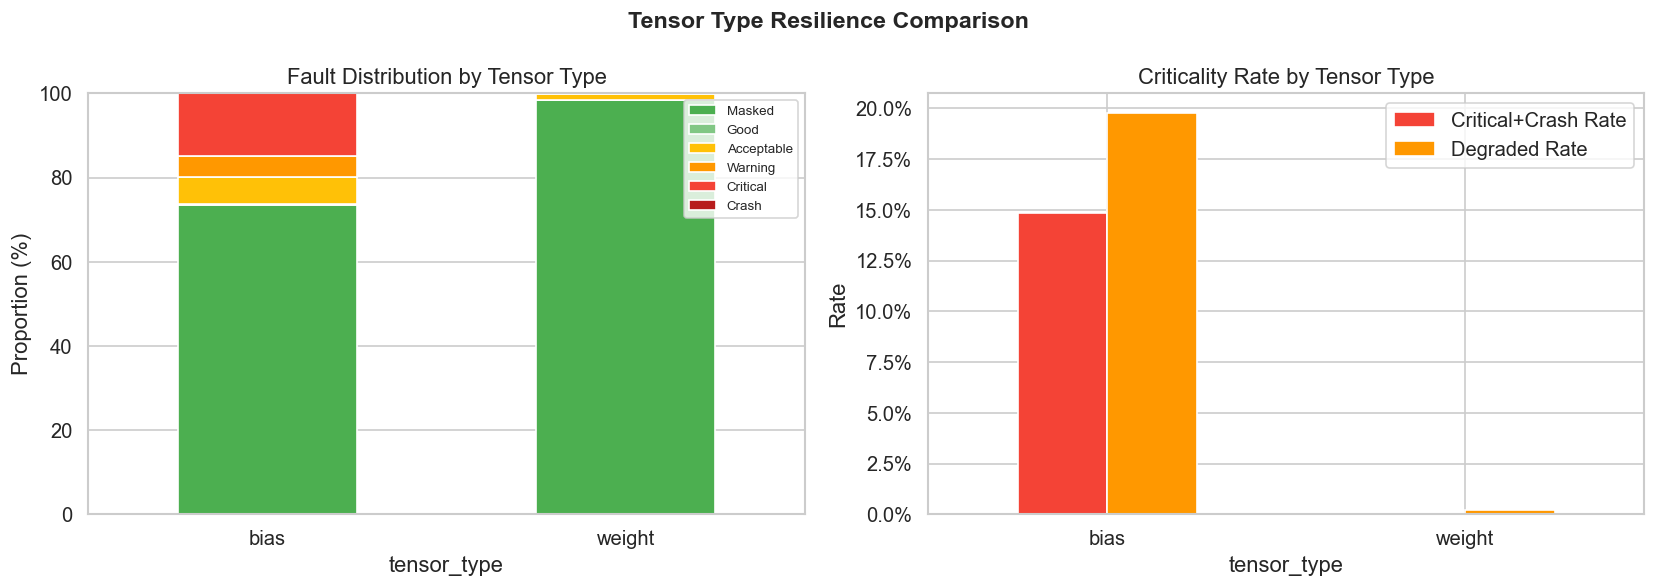

In [11]:
ttype_fc = df.groupby("tensor_type")["fault_class"].value_counts().unstack(fill_value=0)
ttype_fc = ttype_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)
ttype_fc["total"] = ttype_fc.sum(axis=1)
ttype_fc["critical_rate"] = (ttype_fc.get("Critical", 0) + ttype_fc.get("Crash", 0)) / ttype_fc["total"]
ttype_fc["degraded_rate"] = ttype_fc[[c for c in DEGRADED_SET if c in ttype_fc.columns]].sum(axis=1) / ttype_fc["total"]

display(ttype_fc.round(4))

ttype_pct = ttype_fc[SEVERITY_ORDER].div(ttype_fc["total"], axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ttype_pct.plot.bar(
    stacked=True, ax=axes[0],
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white",
)
axes[0].set_ylabel("Proportion (%)")
axes[0].set_title("Fault Distribution by Tensor Type")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].tick_params(axis="x", rotation=0)

# Critical + Crash rate comparison
ttype_crit = ttype_fc[["critical_rate", "degraded_rate"]].copy()
ttype_crit.columns = ["Critical+Crash Rate", "Degraded Rate"]
ttype_crit.plot.bar(ax=axes[1], color=["#F44336", "#FF9800"], edgecolor="white")
axes[1].set_ylabel("Rate")
axes[1].set_title("Criticality Rate by Tensor Type")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].tick_params(axis="x", rotation=0)

fig.suptitle("Tensor Type Resilience Comparison", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_tensor_type_resilience.png", bbox_inches="tight")
plt.show()

## 5. Resilience per Operator Instance

fault_class,total,Masked,Acceptable,Warning,Critical,Crash,critical_rate,degraded_rate
op_label,,,,,,,,
0_CONV_2D,30200,27716,1378,435,670,0,0.0222,0.0366
2_CONV_2D,37700,36516,815,170,199,0,0.0053,0.0098
4_CONV_2D,38393,38210,148,29,6,0,0.0002,0.0009
9_FULLY_CONNECTED,38300,37922,247,101,25,0,0.0007,0.0033
10_FULLY_CONNECTED,36500,35855,309,53,282,0,0.0077,0.0092


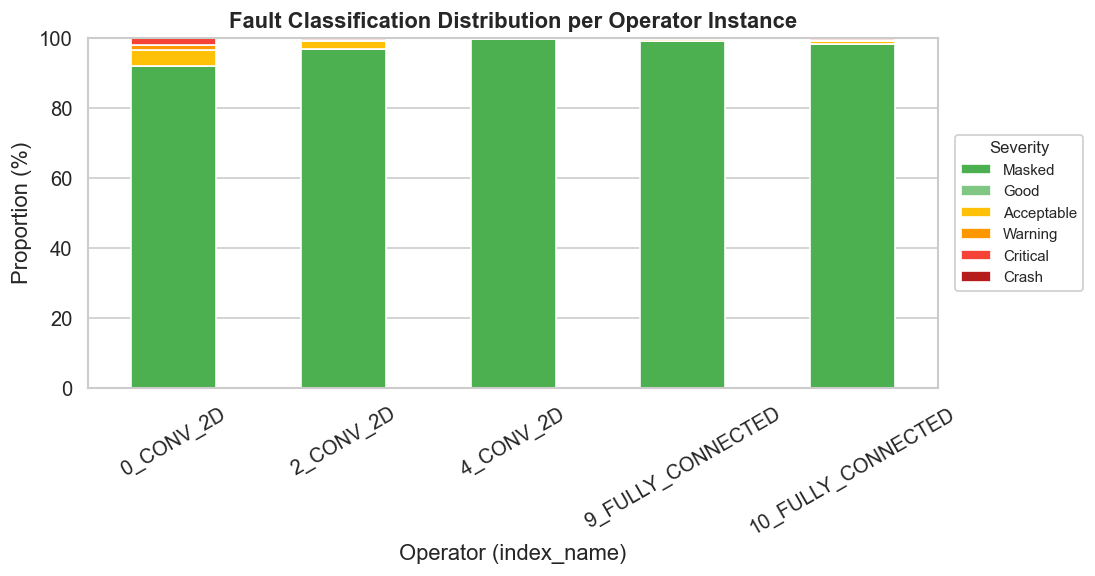

In [12]:
# Build operator instance label: index_name
op_idx = (
    pd.to_numeric(df["operator_index"], errors="coerce")
    .astype("Int64").astype("string").fillna("NA")
)
# Recover operator name from selected_faults
op_name_map = sel.drop_duplicates("op_index").set_index("op_index")["op_name"].to_dict()
df["operator_name"] = df["operator_index"].map(op_name_map).fillna("Unknown")

df["op_label"] = op_idx + "_" + df["operator_name"].astype(str).str.strip()

op_fc = df.groupby("op_label")["fault_class"].value_counts().unstack(fill_value=0)
op_fc = op_fc.reindex(columns=SEVERITY_ORDER, fill_value=0)
op_fc["total"] = op_fc.sum(axis=1)
den = op_fc["total"].replace(0, np.nan)
op_fc["critical_rate"] = (op_fc.get("Critical", 0) + op_fc.get("Crash", 0)) / den
op_fc["degraded_rate"] = op_fc[[c for c in DEGRADED_SET if c in op_fc.columns]].sum(axis=1) / den
op_fc[["critical_rate", "degraded_rate"]] = op_fc[["critical_rate", "degraded_rate"]].fillna(0)

# Sort by operator index
def _sort_key(label: str):
    head = label.split("_", 1)[0]
    try:
        return (0, int(head))
    except ValueError:
        return (1, label)

op_fc = op_fc.loc[sorted(op_fc.index, key=_sort_key)]

display_cols = ["total", "Masked", "Acceptable", "Warning", "Critical", "Crash", "critical_rate", "degraded_rate"]
display(op_fc.reindex(columns=display_cols, fill_value=0).round(4))

op_pct = op_fc[SEVERITY_ORDER].div(den.loc[op_fc.index], axis=0).fillna(0) * 100

fig, ax = plt.subplots(figsize=(11, 5))
op_pct.plot.bar(
    stacked=True, ax=ax,
    color=[SEVERITY_COLORS[c] for c in SEVERITY_ORDER],
    edgecolor="white",
)
ax.set_ylabel("Proportion (%)")
ax.set_xlabel("Operator (index_name)")
ax.set_title("Fault Classification Distribution per Operator Instance", fontweight="bold")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=30)

# Legenda fora do eixo — sem colisão com a última barra
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    title="Severity",
    fontsize=9,
    title_fontsize=10,
    framealpha=0.95,
    borderaxespad=0.0,
)

plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.savefig(RUN_DIR / "fig_classification_per_operator.png", bbox_inches="tight")
plt.show()

## 6. Tensor × Operator Criticality Heatmap

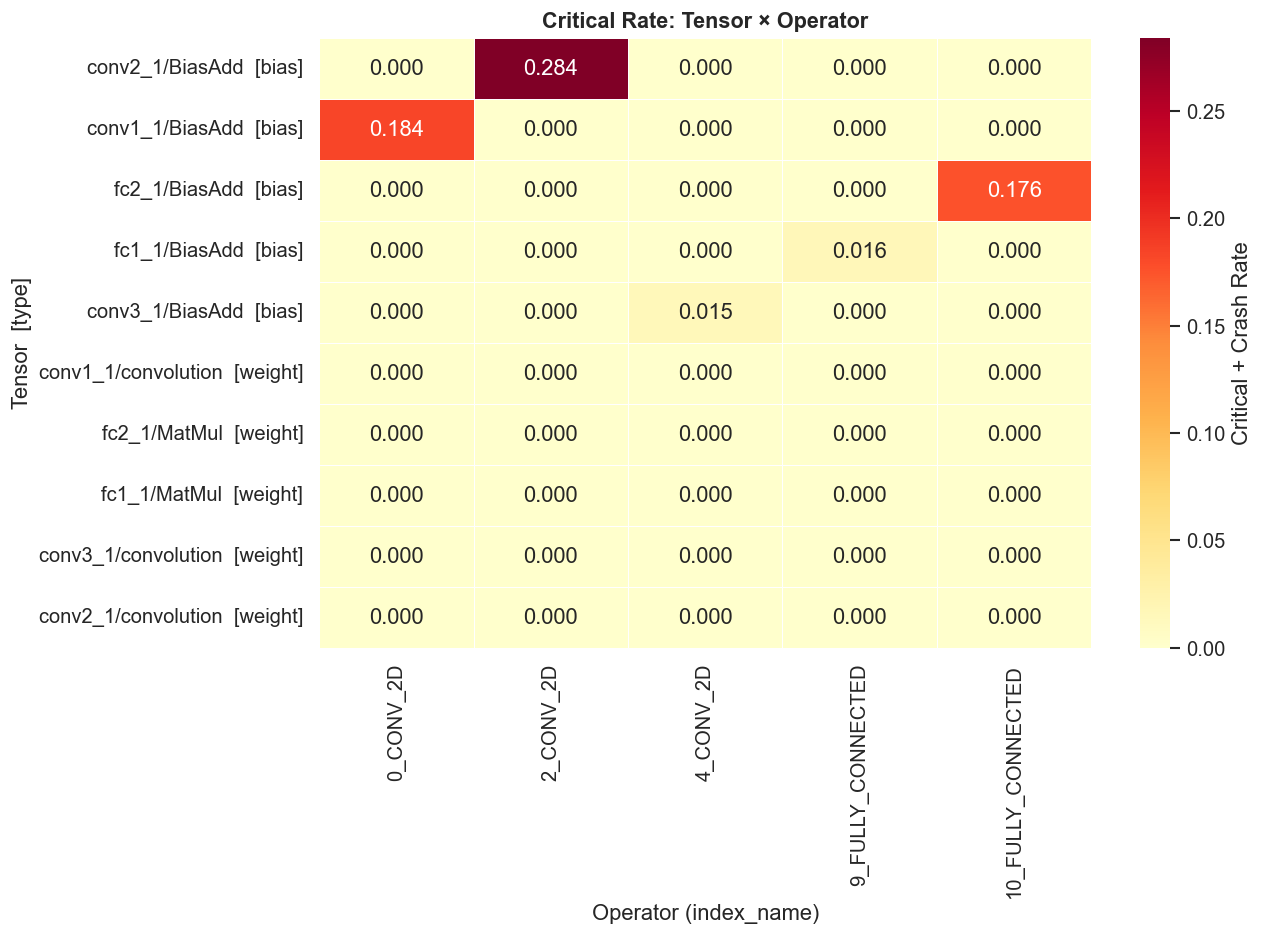

In [13]:
# --- Label de exibição semanticamente correto --------------------------------
# Para tensores fundidos (nome com ';'), prefere o ramo 'BiasAdd' quando presente.
def _display_label(name: str) -> str:
    branches = str(name).split(";")
    chosen = next((b for b in branches if "BiasAdd" in b), branches[-1])
    parts = chosen.split("/")
    return "/".join(parts[-2:]) if len(parts) >= 2 else chosen

# Garante que df possui display_label e tensor_type (caso esta célula rode isolada)
if "display_label" not in df.columns:
    _name_by_idx = (
        df.dropna(subset=["tensor_name"])
          .drop_duplicates("tensor_index")
          .set_index("tensor_index")["tensor_name"]
    )
    display_label_map = {idx: _display_label(n) for idx, n in _name_by_idx.items()}
    assert len(set(display_label_map.values())) == len(display_label_map), (
        "Colisão de display_label detectada"
    )
    df["display_label"] = df["tensor_index"].map(display_label_map)

# Plot label anota o tipo para desambiguar visualmente
type_by_idx = df.drop_duplicates("tensor_index").set_index("tensor_index")["tensor_type"]
plot_label_map = {
    idx: f"{df.loc[df['tensor_index'] == idx, 'display_label'].iloc[0]}  [{t}]"
    for idx, t in type_by_idx.items()
}
df["tensor_plot_label"] = df["tensor_index"].map(plot_label_map)
# ---------------------------------------------------------------------------

def critical_rate(g):
    return g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0.0

# Agrega por tensor_index (chave física) × op_label — depois renomeia para exibição
heatmap_raw = (
    df.groupby(["tensor_index", "op_label"])
      .apply(critical_rate)
      .unstack(fill_value=0)
)

# Ordena tensores pela taxa crítica global (descendente)
tensor_order = (
    df.groupby("tensor_index")
      .apply(critical_rate)
      .sort_values(ascending=False)
      .index
)
heatmap_raw = heatmap_raw.reindex(tensor_order)

# Renomeia o índice físico (tensor_index) para o label de exibição semanticamente correto
idx_to_plot_label = df.drop_duplicates("tensor_index").set_index("tensor_index")["tensor_plot_label"]
heatmap_data = heatmap_raw.rename(index=idx_to_plot_label.to_dict())

# Ordena colunas (operadores) por op_index numérico
def _op_sort_key(label: str):
    head = str(label).split("_", 1)[0]
    try:
        return (0, int(head))
    except ValueError:
        return (1, label)

heatmap_data = heatmap_data[sorted(heatmap_data.columns, key=_op_sort_key)]

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(
    heatmap_data, annot=True, fmt=".3f", cmap="YlOrRd",
    linewidths=0.5, linecolor="white", ax=ax,
    cbar_kws={"label": "Critical + Crash Rate"},
    vmin=0, vmax=max(heatmap_data.max().max(), 0.01),
)
ax.set_title("Critical Rate: Tensor × Operator", fontweight="bold", fontsize=13)
ax.set_ylabel("Tensor  [type]")
ax.set_xlabel("Operator (index_name)")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_heatmap_tensor_operator.png", bbox_inches="tight")
plt.show()

## 7. Bit-Position Vulnerability Analysis
Evaluates whether higher-order bits (MSB) lead to more critical failures than lower-order bits (LSB). In INT8 quantized models, bit 7 is the sign bit.

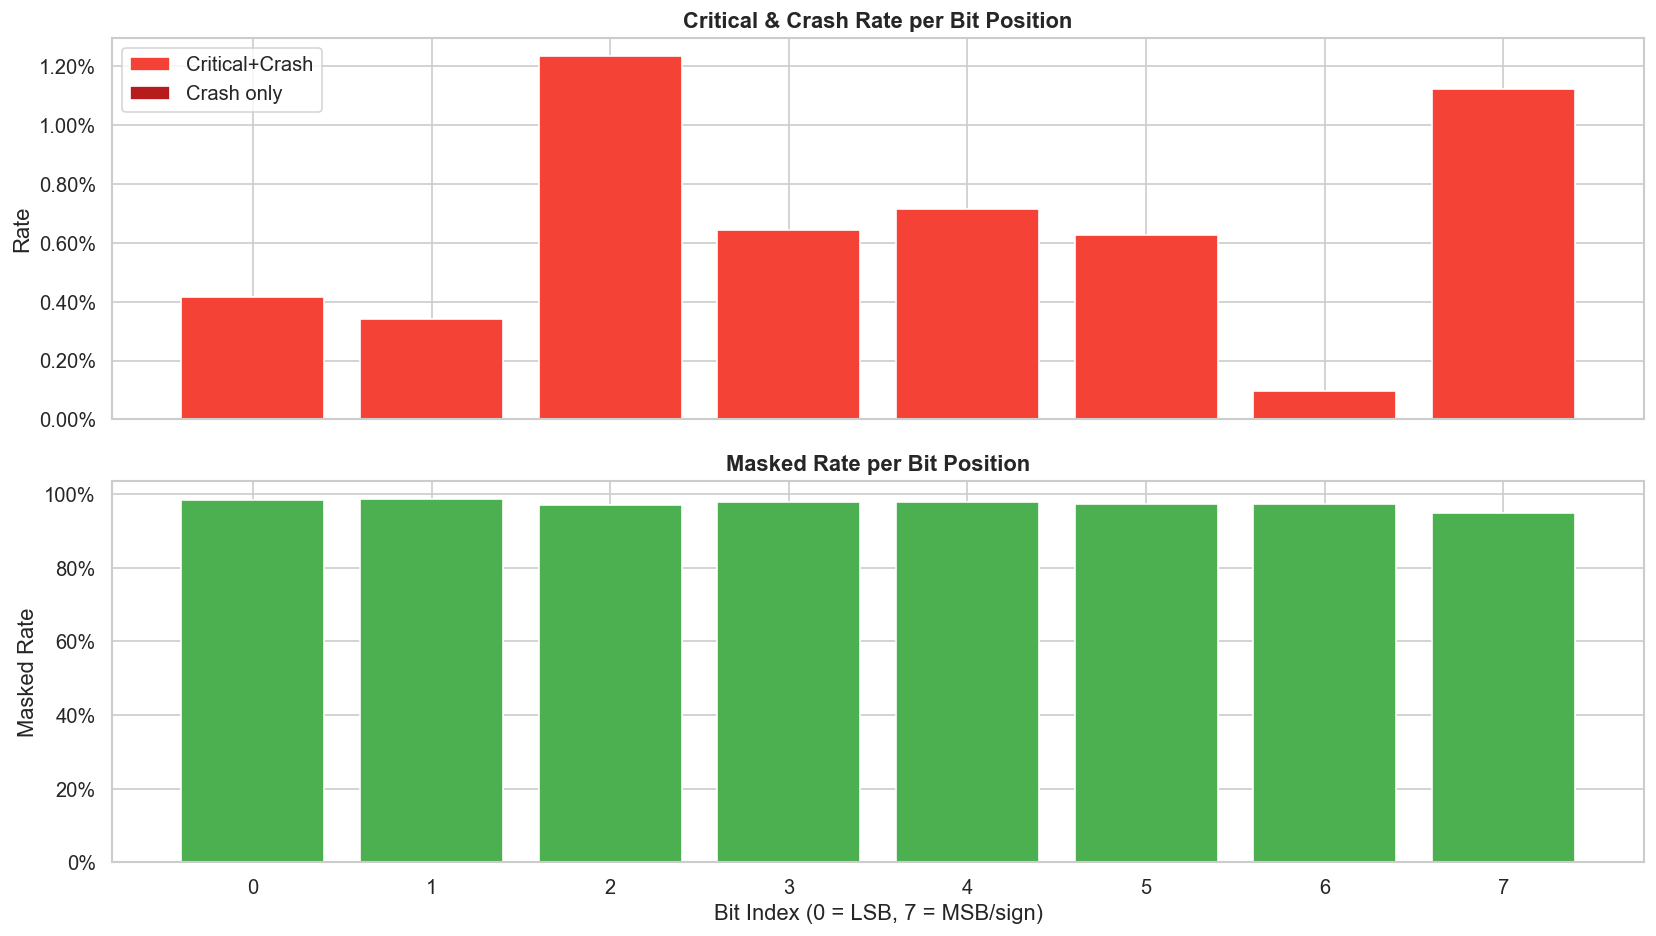

,bit_index,total,critical,degraded,crash,masked,critical_rate,crash_rate,masked_rate
0,0,22900,95,159,0,22550,0.0041,0.0,0.9847
1,1,25100,86,143,0,24759,0.0034,0.0,0.9864
2,2,22900,283,419,0,22210,0.0124,0.0,0.9699
3,3,19400,125,210,0,18949,0.0064,0.0,0.9768
4,4,20700,148,204,0,20226,0.0071,0.0,0.9771
5,5,23993,150,234,0,23340,0.0063,0.0,0.9728
6,6,21700,21,125,0,21078,0.0010,0.0,0.9713
7,7,24400,274,476,0,23107,0.0112,0.0,0.9470


In [14]:
bit_col = "bit_index" if "bit_index" not in df.columns or df["bit_index"].isna().all() else "bit_index"
if "bit_index_sel" in df.columns:
    df["bit_index"] = df["bit_index"].fillna(df["bit_index_sel"])

bit_fc = df.groupby("bit_index").apply(
    lambda g: pd.Series({
        "total": len(g),
        "critical": g["fault_class"].isin(CRITICAL_SET).sum(),
        "degraded": g["fault_class"].isin(DEGRADED_SET).sum(),
        "crash": (g["fault_class"] == "Crash").sum(),
        "masked": (g["fault_class"] == "Masked").sum(),
    })
).reset_index()
bit_fc["bit_index"] = bit_fc["bit_index"].astype(int)
bit_fc["critical_rate"] = bit_fc["critical"] / bit_fc["total"]
bit_fc["crash_rate"] = bit_fc["crash"] / bit_fc["total"]
bit_fc["masked_rate"] = bit_fc["masked"] / bit_fc["total"]
bit_fc = bit_fc.sort_values("bit_index")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].bar(bit_fc["bit_index"], bit_fc["critical_rate"], color="#F44336", label="Critical+Crash")
axes[0].bar(bit_fc["bit_index"], bit_fc["crash_rate"], color="#B71C1C", label="Crash only")
axes[0].set_ylabel("Rate")
axes[0].set_title("Critical & Crash Rate per Bit Position", fontweight="bold")
axes[0].legend()
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

axes[1].bar(bit_fc["bit_index"], bit_fc["masked_rate"], color="#4CAF50")
axes[1].set_ylabel("Masked Rate")
axes[1].set_xlabel("Bit Index (0 = LSB, 7 = MSB/sign)")
axes[1].set_title("Masked Rate per Bit Position", fontweight="bold")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

plt.tight_layout()
plt.savefig(RUN_DIR / "fig_bit_vulnerability.png", bbox_inches="tight")
plt.show()

display(bit_fc.round(4))

## 8. Bit-Position Vulnerability by Tensor Type

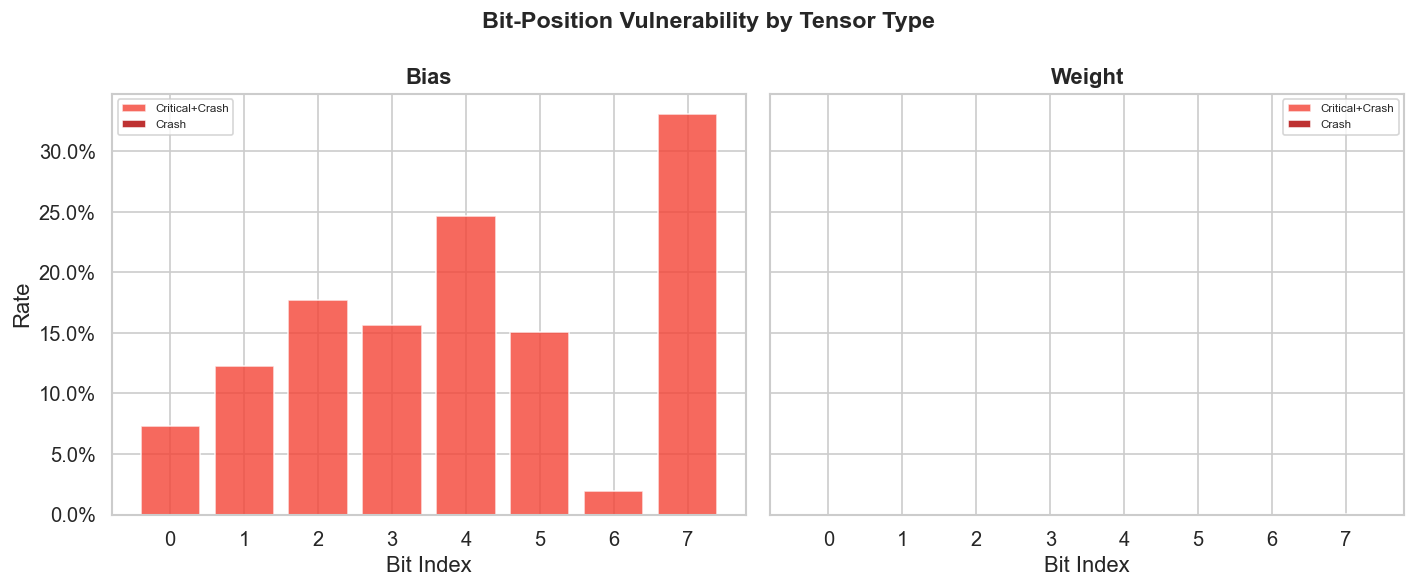

In [15]:
bit_ttype = df.groupby(["tensor_type", "bit_index"]).apply(
    lambda g: pd.Series({
        "total": len(g),
        "critical_rate": g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0,
        "crash_rate": (g["fault_class"] == "Crash").sum() / len(g) if len(g) > 0 else 0,
    })
).reset_index()
bit_ttype["bit_index"] = bit_ttype["bit_index"].astype(int)

ttypes = sorted(bit_ttype["tensor_type"].unique())
fig, axes = plt.subplots(1, len(ttypes), figsize=(6 * len(ttypes), 5), sharey=True)
if len(ttypes) == 1:
    axes = [axes]

for ax, tt in zip(axes, ttypes):
    subset = bit_ttype[bit_ttype["tensor_type"] == tt].sort_values("bit_index")
    ax.bar(subset["bit_index"], subset["critical_rate"], color="#F44336", alpha=0.8, label="Critical+Crash")
    ax.bar(subset["bit_index"], subset["crash_rate"], color="#B71C1C", alpha=0.9, label="Crash")
    ax.set_title(f"{tt.title()}", fontweight="bold")
    ax.set_xlabel("Bit Index")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.legend(fontsize=7)

axes[0].set_ylabel("Rate")
fig.suptitle("Bit-Position Vulnerability by Tensor Type", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_bit_vulnerability_by_type.png", bbox_inches="tight")
plt.show()

## 9. Critical Failure Deep-Dive

Total critical/crash inferences: 1,182 (0.65%)
Unique faults causing critical/crash: 35 / 1811



,,fault_class,Critical,Crash,total_critical
tensor_index,display_label,tensor_type,,,
12.0,conv1_1/BiasAdd,bias,661,0,661
4.0,fc2_1/BiasAdd,bias,282,0,282
10.0,conv2_1/BiasAdd,bias,199,0,199
6.0,fc1_1/BiasAdd,bias,25,0,25
13.0,conv1_1/convolution,weight,9,0,9
8.0,conv3_1/BiasAdd,bias,6,0,6


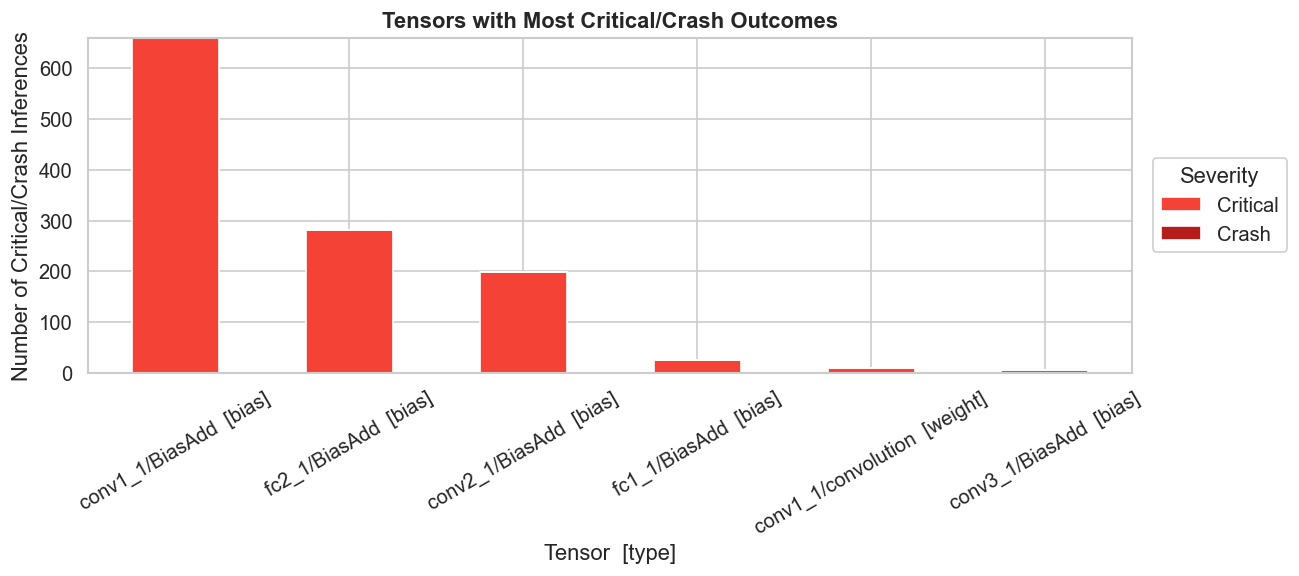

In [16]:
# --- Label de exibição semanticamente correto (reaproveita se já existir) -----
def _display_label(name: str) -> str:
    branches = str(name).split(";")
    chosen = next((b for b in branches if "BiasAdd" in b), branches[-1])
    parts = chosen.split("/")
    return "/".join(parts[-2:]) if len(parts) >= 2 else chosen

if "display_label" not in df.columns:
    _name_by_idx = (
        df.dropna(subset=["tensor_name"])
          .drop_duplicates("tensor_index")
          .set_index("tensor_index")["tensor_name"]
    )
    display_label_map = {idx: _display_label(n) for idx, n in _name_by_idx.items()}
    assert len(set(display_label_map.values())) == len(display_label_map), (
        "Colisão de display_label detectada"
    )
    df["display_label"] = df["tensor_index"].map(display_label_map)

# Mapa tensor_index -> "label  [type]" para exibição
_meta = df.drop_duplicates("tensor_index").set_index("tensor_index")
idx_to_plot_label = (_meta["display_label"] + "  [" + _meta["tensor_type"] + "]").to_dict()
# -----------------------------------------------------------------------------

crit_df = df[df["fault_class"].isin(CRITICAL_SET)].copy()
print(f"Total critical/crash inferences: {len(crit_df):,} ({len(crit_df)/len(df)*100:.2f}%)")
print(f"Unique faults causing critical/crash: {crit_df['fault_id'].nunique()} / {df['fault_id'].nunique()}")
print()

# Agrega por tensor_index (chave física); display_label/tensor_type apenas como metadata
crash_by_tensor = (
    crit_df.groupby(["tensor_index", "display_label", "tensor_type"])["fault_class"]
           .value_counts()
           .unstack(fill_value=0)
)
# Garante que ambas as classes críticas estão presentes como colunas
for c in CRITICAL_SET:
    if c not in crash_by_tensor.columns:
        crash_by_tensor[c] = 0

crash_by_tensor["total_critical"] = crash_by_tensor[list(CRITICAL_SET)].sum(axis=1)
crash_by_tensor = crash_by_tensor.sort_values("total_critical", ascending=False)

display(crash_by_tensor)

# Prepara DataFrame de plot com label semanticamente correto e ordem preservada
crash_plot = crash_by_tensor.reset_index()
crash_plot["plot_label"] = (
    crash_plot["display_label"] + "  [" + crash_plot["tensor_type"] + "]"
)
crash_plot = crash_plot.set_index("plot_label")

plot_cols = [c for c in crash_plot.columns
             if c not in {"total_critical", "tensor_index", "display_label", "tensor_type"}]
# Ordena colunas seguindo SEVERITY_ORDER quando aplicável
plot_cols = [c for c in SEVERITY_ORDER if c in plot_cols] + \
            [c for c in plot_cols if c not in SEVERITY_ORDER]
colors_stacked = [SEVERITY_COLORS.get(c, "#999") for c in plot_cols]

fig, ax = plt.subplots(figsize=(13, 5))
crash_plot[plot_cols].plot.bar(
    stacked=True, ax=ax, color=colors_stacked, edgecolor="white",
)
ax.set_ylabel("Number of Critical/Crash Inferences")
ax.set_xlabel("Tensor  [type]")
ax.set_title("Tensors with Most Critical/Crash Outcomes", fontweight="bold")
ax.tick_params(axis="x", rotation=30)

# Legenda fora do eixo — sem colisão com a última barra
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    title="Severity",
    framealpha=0.95,
    borderaxespad=0.0,
)

plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.savefig(RUN_DIR / "fig_critical_by_tensor.png", bbox_inches="tight")
plt.show()

## 10. Per-Fault Aggregated Vulnerability
For each unique fault injection, compute the fraction of images classified as critical/crash to identify the **most dangerous single-bit faults**.

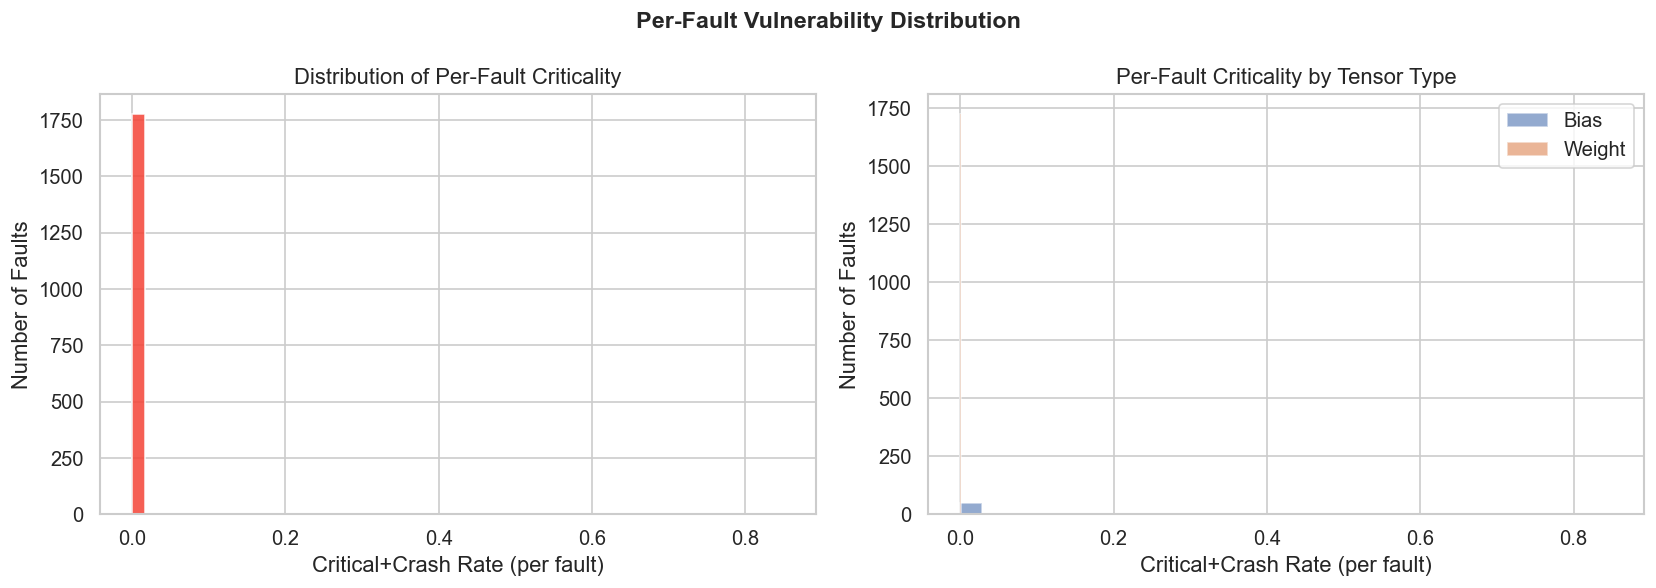


Top 20 most dangerous faults (by critical_rate):


,fault_id,tensor_label,tensor_type,bit_index,op_label,n_images,n_critical,n_crash,critical_rate
0,499050,fc2_1/BiasAdd,bias,2.0,10_FULLY_CONNECTED,100,85,0,0.85
1,1354,conv1_1/Squeeze,bias,2.0,0_CONV_2D,100,83,0,0.83
2,1355,conv1_1/Squeeze,bias,3.0,0_CONV_2D,100,83,0,0.83
3,499151,fc2_1/BiasAdd,bias,7.0,10_FULLY_CONNECTED,100,81,0,0.81
4,1252,conv1_1/Squeeze,bias,4.0,0_CONV_2D,100,76,0,0.76
5,1253,conv1_1/Squeeze,bias,5.0,0_CONV_2D,100,76,0,0.76
6,1255,conv1_1/Squeeze,bias,7.0,0_CONV_2D,100,76,0,0.76
7,1250,conv1_1/Squeeze,bias,2.0,0_CONV_2D,100,75,0,0.75
8,20649,conv2_1/Squeeze,bias,1.0,2_CONV_2D,100,69,0,0.69
9,20653,conv2_1/Squeeze,bias,5.0,2_CONV_2D,100,69,0,0.69


In [17]:
fault_agg = df.groupby("fault_id").apply(
    lambda g: pd.Series({
        "tensor_label": g["tensor_label"].iloc[0],
        "tensor_type": g["tensor_type"].iloc[0],
        "bit_index": g["bit_index"].iloc[0],
        "operator_index": g["operator_index"].iloc[0],
        "op_label": g["op_label"].iloc[0] if "op_label" in g.columns else "",
        "n_images": len(g),
        "n_critical": g["fault_class"].isin(CRITICAL_SET).sum(),
        "n_crash": (g["fault_class"] == "Crash").sum(),
        "n_masked": (g["fault_class"] == "Masked").sum(),
        "critical_rate": g["fault_class"].isin(CRITICAL_SET).sum() / len(g),
        "crash_rate": (g["fault_class"] == "Crash").sum() / len(g),
    })
).reset_index()

# Distribution of per-fault critical rate
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(fault_agg["critical_rate"], bins=50, color="#F44336", edgecolor="white", alpha=0.85)
axes[0].set_xlabel("Critical+Crash Rate (per fault)")
axes[0].set_ylabel("Number of Faults")
axes[0].set_title("Distribution of Per-Fault Criticality")

# Per-fault critical rate by tensor type
for tt in sorted(fault_agg["tensor_type"].unique()):
    subset = fault_agg[fault_agg["tensor_type"] == tt]
    axes[1].hist(subset["critical_rate"], bins=30, alpha=0.6, label=tt.title(), edgecolor="white")
axes[1].set_xlabel("Critical+Crash Rate (per fault)")
axes[1].set_ylabel("Number of Faults")
axes[1].set_title("Per-Fault Criticality by Tensor Type")
axes[1].legend()

fig.suptitle("Per-Fault Vulnerability Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_per_fault_distribution.png", bbox_inches="tight")
plt.show()

# Top 20 most dangerous faults
print("\nTop 20 most dangerous faults (by critical_rate):")
display(fault_agg.nlargest(20, "critical_rate")[
    ["fault_id", "tensor_label", "tensor_type", "bit_index",
     "op_label", "n_images", "n_critical", "n_crash", "critical_rate"]
].reset_index(drop=True))

## 13. Impact on Model Accuracy
Compare the **golden accuracy** (no fault) against the effective accuracy under each fault scenario.

Golden Accuracy : 0.9900 (99.00%)
Faulty Accuracy : 0.9836 (98.36%)
Accuracy Drop   : 0.64 pp


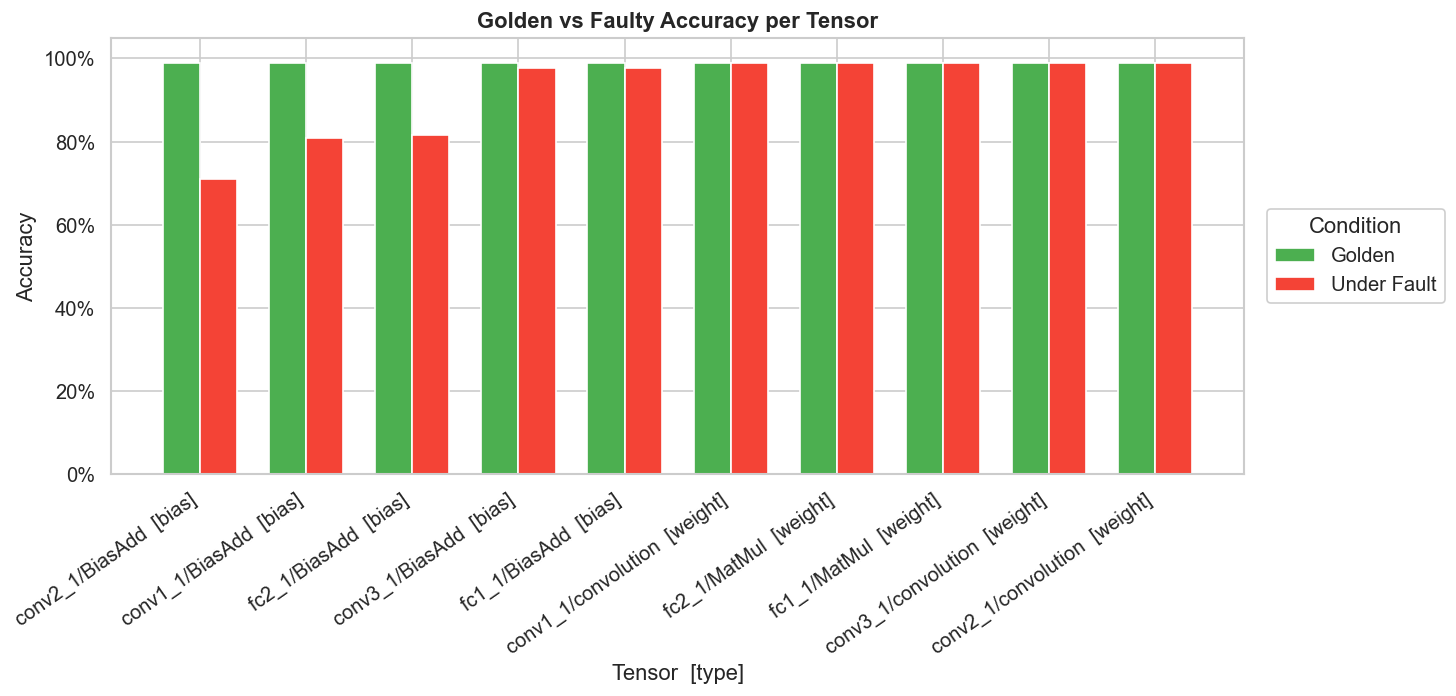

,faulty_accuracy,golden_accuracy,accuracy_drop
tensor,,,
conv2_1/BiasAdd [bias],0.7100,0.9900,0.2800
conv1_1/BiasAdd [bias],0.8089,0.9900,0.1811
fc2_1/BiasAdd [bias],0.8156,0.9900,0.1744
conv3_1/BiasAdd [bias],0.9771,0.9898,0.0127
fc1_1/BiasAdd [bias],0.9775,0.9900,0.0125
conv1_1/convolution [weight],0.9897,0.9900,0.0003
fc2_1/MatMul [weight],0.9900,0.9900,0.0000
fc1_1/MatMul [weight],0.9900,0.9900,0.0000
conv3_1/convolution [weight],0.9900,0.9900,0.0000


In [22]:
# --- Label de exibição semanticamente correto (reaproveita se já existir) -----
def _display_label(name: str) -> str:
    branches = str(name).split(";")
    chosen = next((b for b in branches if "BiasAdd" in b), branches[-1])
    parts = chosen.split("/")
    return "/".join(parts[-2:]) if len(parts) >= 2 else chosen

if "display_label" not in df.columns:
    _name_by_idx = (
        df.dropna(subset=["tensor_name"])
          .drop_duplicates("tensor_index")
          .set_index("tensor_index")["tensor_name"]
    )
    display_label_map = {idx: _display_label(n) for idx, n in _name_by_idx.items()}
    assert len(set(display_label_map.values())) == len(display_label_map), (
        "Colisão de display_label detectada"
    )
    df["display_label"] = df["tensor_index"].map(display_label_map)

_meta = df.drop_duplicates("tensor_index").set_index("tensor_index")
idx_to_plot_label = (_meta["display_label"] + "  [" + _meta["tensor_type"] + "]").to_dict()
# -----------------------------------------------------------------------------

# Golden accuracy
golden_correct = (df["golden_pred_class_ref"] == df["label"]).sum()
golden_acc = golden_correct / len(df)

# Faulty accuracy
faulty_correct = (df["pred_class"] == df["label"]).sum()
faulty_acc = faulty_correct / len(df)

print(f"Golden Accuracy : {golden_acc:.4f} ({golden_acc*100:.2f}%)")
print(f"Faulty Accuracy : {faulty_acc:.4f} ({faulty_acc*100:.2f}%)")
print(f"Accuracy Drop   : {(golden_acc - faulty_acc)*100:.2f} pp")

# Accuracy per tensor — agrupa por tensor_index (chave física)
acc_per_tensor = df.groupby("tensor_index").apply(
    lambda g: pd.Series({
        "faulty_accuracy": (g["pred_class"] == g["label"]).sum() / len(g),
        "golden_accuracy": (g["golden_pred_class_ref"] == g["label"]).sum() / len(g),
        "accuracy_drop": (
            (g["golden_pred_class_ref"] == g["label"]).sum()
            - (g["pred_class"] == g["label"]).sum()
        ) / len(g),
    })
).sort_values("accuracy_drop", ascending=False)

# Renomeia índice físico para label de exibição semanticamente correto
acc_per_tensor.index = acc_per_tensor.index.map(idx_to_plot_label)
acc_per_tensor.index.name = "tensor"

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(acc_per_tensor))
w = 0.35
ax.bar(x - w/2, acc_per_tensor["golden_accuracy"], w,
       label="Golden", color="#4CAF50", edgecolor="white")
ax.bar(x + w/2, acc_per_tensor["faulty_accuracy"], w,
       label="Under Fault", color="#F44336", edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(acc_per_tensor.index, rotation=35, ha="right")
ax.set_ylabel("Accuracy")
ax.set_xlabel("Tensor  [type]")
ax.set_title("Golden vs Faulty Accuracy per Tensor", fontweight="bold")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylim(0, 1.05)

# Legenda fora do eixo — sem colisão com as barras
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    title="Condition",
    framealpha=0.95,
    borderaxespad=0.0,
)

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.savefig(RUN_DIR / "fig_accuracy_per_tensor.png", bbox_inches="tight")
plt.show()

display(acc_per_tensor.round(4))

## 14. Accuracy per Operator Instance

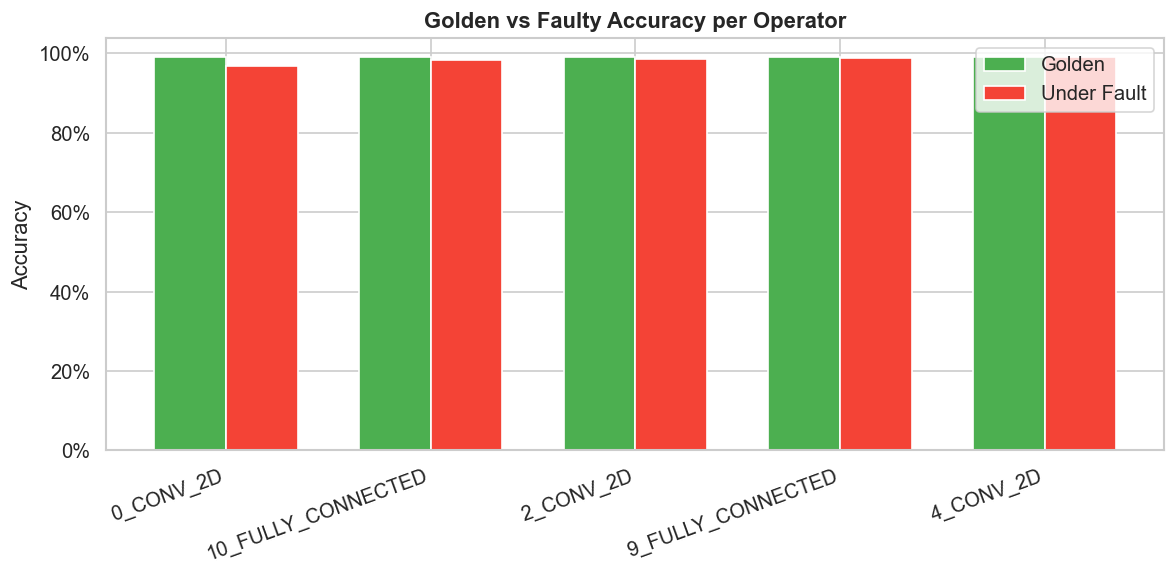

,faulty_accuracy,golden_accuracy,accuracy_drop
op_label,,,
0_CONV_2D,0.9682,0.99,0.0218
10_FULLY_CONNECTED,0.9824,0.99,0.0076
2_CONV_2D,0.9848,0.99,0.0052
9_FULLY_CONNECTED,0.9895,0.99,0.0005
4_CONV_2D,0.9899,0.99,0.0001


In [21]:
acc_per_op = df.groupby("op_label").apply(
    lambda g: pd.Series({
        "faulty_accuracy": (g["pred_class"] == g["label"]).sum() / len(g),
        "golden_accuracy": (g["golden_pred_class_ref"] == g["label"]).sum() / len(g),
        "accuracy_drop": ((g["golden_pred_class_ref"] == g["label"]).sum() - (g["pred_class"] == g["label"]).sum()) / len(g),
    })
).sort_values("accuracy_drop", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(acc_per_op))
w = 0.35
ax.bar(x - w/2, acc_per_op["golden_accuracy"], w, label="Golden", color="#4CAF50", edgecolor="white")
ax.bar(x + w/2, acc_per_op["faulty_accuracy"], w, label="Under Fault", color="#F44336", edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(acc_per_op.index, rotation=20, ha="right")
ax.set_ylabel("Accuracy")
ax.set_title("Golden vs Faulty Accuracy per Operator", fontweight="bold")
ax.legend()
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_accuracy_per_operator.png", bbox_inches="tight")
plt.show()

display(acc_per_op.round(4))

## 15. Physical Address Space Analysis
Memory fault injection targets specific byte addresses in the model flatbuffer. This section maps critical faults to their physical address ranges to identify **hot regions** in the memory layout.

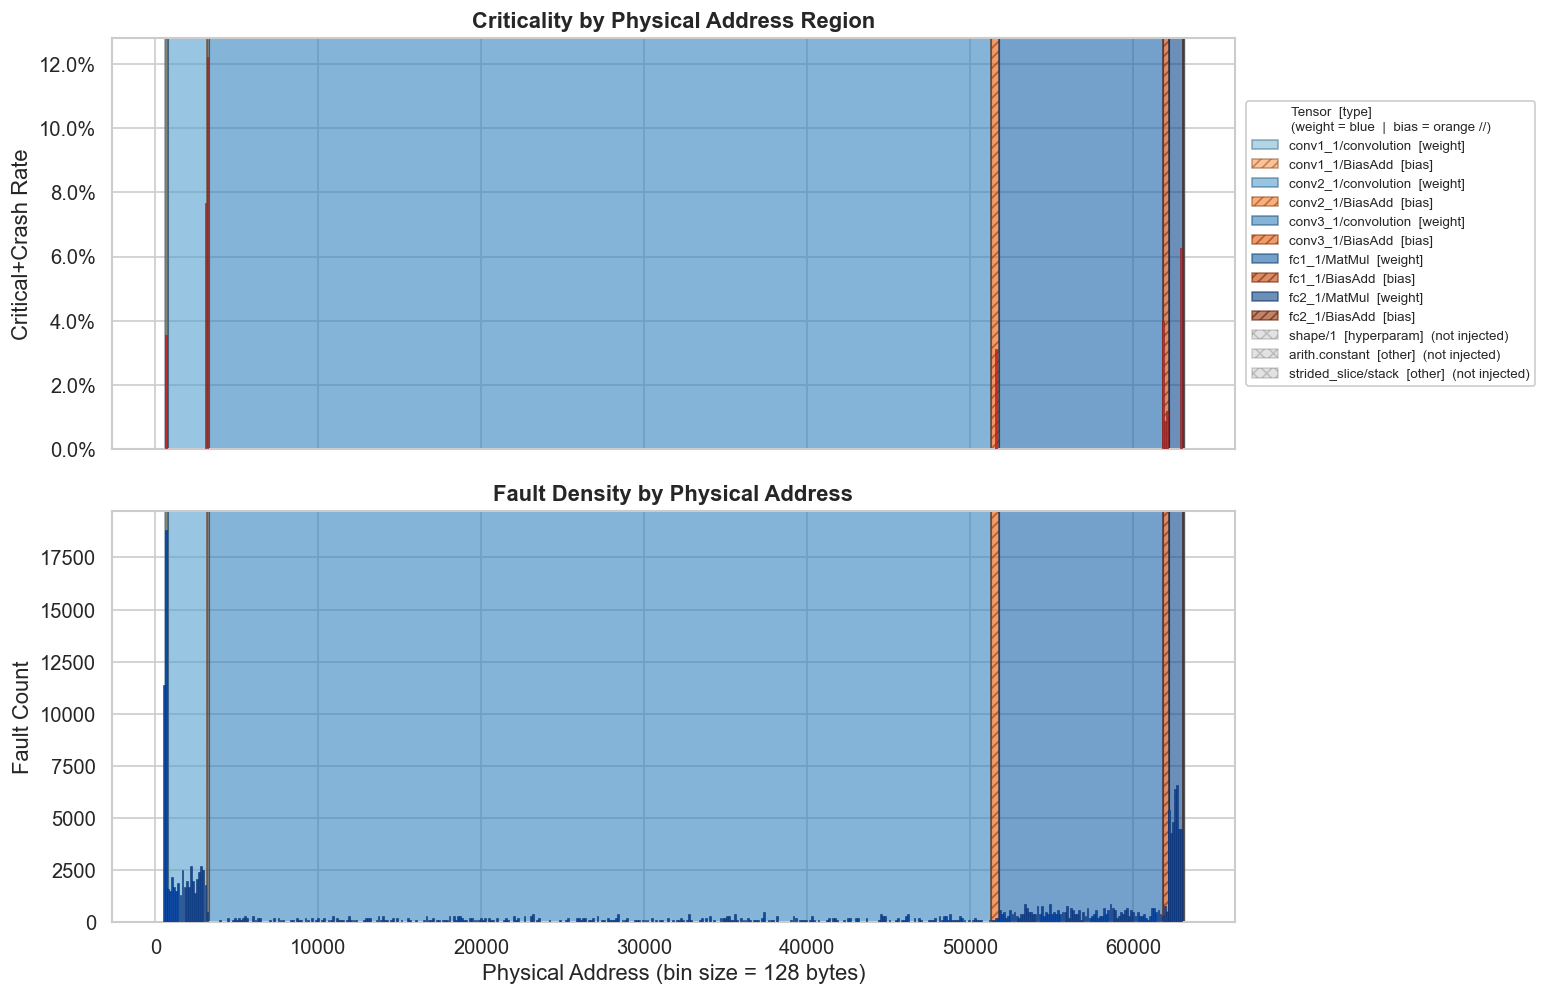

Top 10 most critical address regions:


,addr_bin,tensor,total,critical,critical_rate,degraded_rate
0,3200,conv2_1/BiasAdd [bias],500.0,61.0,0.1220,0.1400
1,3072,conv2_1/convolution [weight],1800.0,138.0,0.0767,0.0894
2,62976,fc2_1/MatMul [weight],4500.0,282.0,0.0627,0.0700
3,61824,fc1_1/MatMul [weight],300.0,12.0,0.0400,0.1067
4,640,conv1_1/convolution [weight],18800.0,670.0,0.0356,0.0555
5,51584,conv3_1/BiasAdd [bias],193.0,6.0,0.0311,0.0725
6,62080,fc1_1/BiasAdd [bias],500.0,6.0,0.0120,0.0760
7,61952,fc1_1/BiasAdd [bias],800.0,7.0,0.0088,0.0500
8,512,—,11400.0,0.0,0.0000,0.0054
9,768,—,1600.0,0.0,0.0000,0.0031



Tensor classification summary:


,tensor_index,display_label,tensor_type,injected,global_offset,bytes
0,13,conv1_1/convolution,weight,True,576,150
1,12,conv1_1/BiasAdd,bias,True,740,24
2,11,conv2_1/convolution,weight,True,776,2400
3,10,conv2_1/BiasAdd,bias,True,3188,64
4,9,conv3_1/convolution,weight,True,3264,48000
5,8,conv3_1/BiasAdd,bias,True,51276,480
6,7,fc1_1/MatMul,weight,True,51768,10080
7,6,fc1_1/BiasAdd,bias,True,61860,336
8,5,fc2_1/MatMul,weight,True,62208,840
9,4,fc2_1/BiasAdd,bias,True,63060,40


In [20]:
# --- Label de exibição semanticamente correto (reaproveita se já existir) -----
def _display_label(name: str) -> str:
    branches = str(name).split(";")
    chosen = next((b for b in branches if "BiasAdd" in b), branches[-1])
    parts = chosen.split("/")
    return "/".join(parts[-2:]) if len(parts) >= 2 else chosen

def _classify_tensor(name: str) -> str:
    n = str(name).lower()
    if "bias" in n:
        return "bias"
    if any(k in n for k in (
        "reduction_indices", "/axis", "/perm", "/shape", "/paddings",
        "/block_shape", "/crops",
    )):
        return "hyperparam"
    if any(k in n for k in ("matmul", "convolution", "kernel", "depthwise", "filter")):
        return "weight"
    return "other"

def _layer_key(display_label: str) -> str:
    return str(display_label).split("/")[0]

if "display_label" not in df.columns:
    _name_by_idx = (
        df.dropna(subset=["tensor_name"])
          .drop_duplicates("tensor_index")
          .set_index("tensor_index")["tensor_name"]
    )
    display_label_map = {idx: _display_label(n) for idx, n in _name_by_idx.items()}
    assert len(set(display_label_map.values())) == len(display_label_map), (
        "Colisão de display_label detectada"
    )
    df["display_label"] = df["tensor_index"].map(display_label_map)
# -----------------------------------------------------------------------------

# Enrich df with global_byte_offset if available
if "global_byte_offset" not in df.columns or df["global_byte_offset"].isna().all():
    if "global_byte_offset_sel" in df.columns:
        df["global_byte_offset"] = df["global_byte_offset_sel"]
    else:
        offset_map = tensor_map.set_index("tensor_index")["global_offset"].to_dict()
        df["tensor_global_offset"] = df["tensor_index"].map(offset_map)
        byte_in = df["byte_in_tensor"] if "byte_in_tensor" in df.columns else 0
        df["global_byte_offset"] = df["tensor_global_offset"] + byte_in

BIN_SIZE = 128
df["addr_bin"] = (df["global_byte_offset"] // BIN_SIZE).astype("Int64") * BIN_SIZE

addr_fc = df.dropna(subset=["addr_bin"]).groupby("addr_bin").apply(
    lambda g: pd.Series({
        "total": len(g),
        "critical": g["fault_class"].isin(CRITICAL_SET).sum(),
        "masked": (g["fault_class"] == "Masked").sum(),
        "critical_rate": g["fault_class"].isin(CRITICAL_SET).sum() / len(g),
        "degraded_rate": g["fault_class"].isin(DEGRADED_SET).sum() / len(g),
    })
).reset_index()
addr_fc = addr_fc.sort_values("addr_bin")

# --- Metadata dos tensores para overlay --------------------------------------
injected_set = set(df["tensor_index"].dropna().unique().tolist())

tmap = tensor_map.copy()
tmap = tmap[tmap["global_offset"] >= 0].reset_index(drop=True)
tmap["display_label"] = tmap["name"].apply(_display_label)
tmap["tensor_type"]   = tmap["name"].apply(_classify_tensor)
tmap["injected"]      = tmap["tensor_index"].isin(injected_set)
tmap["layer_key"]     = tmap["display_label"].apply(_layer_key)

tmap["legend_label"] = tmap.apply(
    lambda r: f"{r['display_label']}  [{r['tensor_type']}]"
              + ("" if r["injected"] else "  (not injected)"),
    axis=1,
)
tmap = tmap.sort_values("global_offset").reset_index(drop=True)

# --- PALETA: contraste FORTE weight (azul) vs bias (laranja) -----------------
_layer_order = (
    tmap.loc[tmap["injected"]]
        .sort_values("global_offset")
        .drop_duplicates("layer_key")["layer_key"].tolist()
)
_n_layers = max(len(_layer_order), 1)
_shade_pos = np.linspace(0.45, 0.92, _n_layers)

_weight_by_layer = {lk: plt.cm.Blues(_shade_pos[i])[:3]
                    for i, lk in enumerate(_layer_order)}
_bias_by_layer   = {lk: plt.cm.Oranges(_shade_pos[i])[:3]
                    for i, lk in enumerate(_layer_order)}

GRAY = (0.55, 0.55, 0.55)

def _color_for(row):
    if not row["injected"]:
        return GRAY
    if row["tensor_type"] == "weight":
        return _weight_by_layer.get(row["layer_key"], (0.2, 0.2, 0.6))
    if row["tensor_type"] == "bias":
        return _bias_by_layer.get(row["layer_key"], (0.9, 0.5, 0.1))
    return GRAY

def _hatch_for(row) -> str:
    # Sempre retorna string (nunca None) para evitar NaN no pandas.
    # String vazia é convertida para None na hora de desenhar.
    if not row["injected"]:
        return "xxx"
    if row["tensor_type"] == "bias":
        return "////"
    return ""  # weight: sólido

def _darken(rgb, t=0.40):
    return tuple(rgb[i] * (1 - t) for i in range(3))

tmap["face_color"] = tmap.apply(_color_for, axis=1)
tmap["hatch"]      = tmap.apply(_hatch_for, axis=1).astype(str)
tmap["edge_color"] = tmap["face_color"].apply(lambda c: _darken(c, 0.40))
# -----------------------------------------------------------------------------

SHADOW_ALPHA_INJ  = 0.60
SHADOW_ALPHA_NONI = 0.25

fig, axes = plt.subplots(2, 1, figsize=(16, 8.5), sharex=True)

def _draw_overlay(ax, with_labels: bool):
    for _, trow in tmap.iterrows():
        start = int(trow["global_offset"])
        end   = start + int(trow["length_bytes"])
        is_inj = bool(trow["injected"])
        raw_hatch = trow["hatch"]
        # Converte string vazia / NaN em None (valor aceito pelo matplotlib)
        if not isinstance(raw_hatch, str) or raw_hatch == "":
            hatch_val = None
        else:
            hatch_val = raw_hatch
        ax.axvspan(
            start, end,
            facecolor=tuple(trow["face_color"]),
            edgecolor=tuple(trow["edge_color"]),
            linewidth=0.9,
            alpha=SHADOW_ALPHA_INJ if is_inj else SHADOW_ALPHA_NONI,
            hatch=hatch_val,
            label=trow["legend_label"] if with_labels else None,
            zorder=1,
        )
        ax.axvline(start, color=tuple(trow["edge_color"]),
                   linewidth=0.7, alpha=0.7, zorder=2)

# --- Painel 1: criticalidade -------------------------------------------------
_draw_overlay(axes[0], with_labels=True)
axes[0].bar(addr_fc["addr_bin"], addr_fc["critical_rate"], width=BIN_SIZE * 0.9,
            color="#C62828", edgecolor="#7F1D1D", linewidth=0.3,
            alpha=0.98, zorder=3)
axes[0].set_ylabel("Critical+Crash Rate")
axes[0].set_title("Criticality by Physical Address Region", fontweight="bold")
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(1.0))

axes[0].legend(
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    fontsize=8,
    title="Tensor  [type]\n(weight = blue  |  bias = orange //)",
    title_fontsize=8,
    framealpha=0.97,
    borderaxespad=0.0,
    ncol=1,
)

# --- Painel 2: densidade -----------------------------------------------------
_draw_overlay(axes[1], with_labels=False)
axes[1].bar(addr_fc["addr_bin"], addr_fc["total"], width=BIN_SIZE * 0.9,
            color="#0D47A1", edgecolor="#082C6B", linewidth=0.3,
            alpha=0.98, zorder=3)
axes[1].set_ylabel("Fault Count")
axes[1].set_xlabel(f"Physical Address (bin size = {BIN_SIZE} bytes)")
axes[1].set_title("Fault Density by Physical Address", fontweight="bold")

plt.tight_layout(rect=[0, 0, 0.82, 1])
plt.savefig(RUN_DIR / "fig_physical_address_criticality.png", bbox_inches="tight")
plt.show()

# --- Top 10 hottest address regions ------------------------------------------
def _tensor_at_offset(offset: int) -> str:
    hit = tmap[(tmap["global_offset"] <= offset) &
               (offset < tmap["global_offset"] + tmap["length_bytes"])]
    return hit["legend_label"].iloc[0] if len(hit) else "—"

top_crit = addr_fc.nlargest(10, "critical_rate")[
    ["addr_bin", "total", "critical", "critical_rate", "degraded_rate"]
].reset_index(drop=True)
top_crit["tensor"] = top_crit["addr_bin"].apply(_tensor_at_offset)

print("Top 10 most critical address regions:")
display(top_crit[["addr_bin", "tensor", "total", "critical",
                  "critical_rate", "degraded_rate"]].round(4))

print("\nTensor classification summary:")
display(
    tmap[["tensor_index", "display_label", "tensor_type", "injected",
          "global_offset", "length_bytes"]]
    .rename(columns={"length_bytes": "bytes"})
)

## 16. Physical Heatmap: Tensor × Byte-Offset Bin
A 2D heatmap showing critical rates across the physical memory layout, grouped by tensor and byte-offset bin.

heat_data: 10 tensores × 227 bins
Max critical rate observado: 0.3880


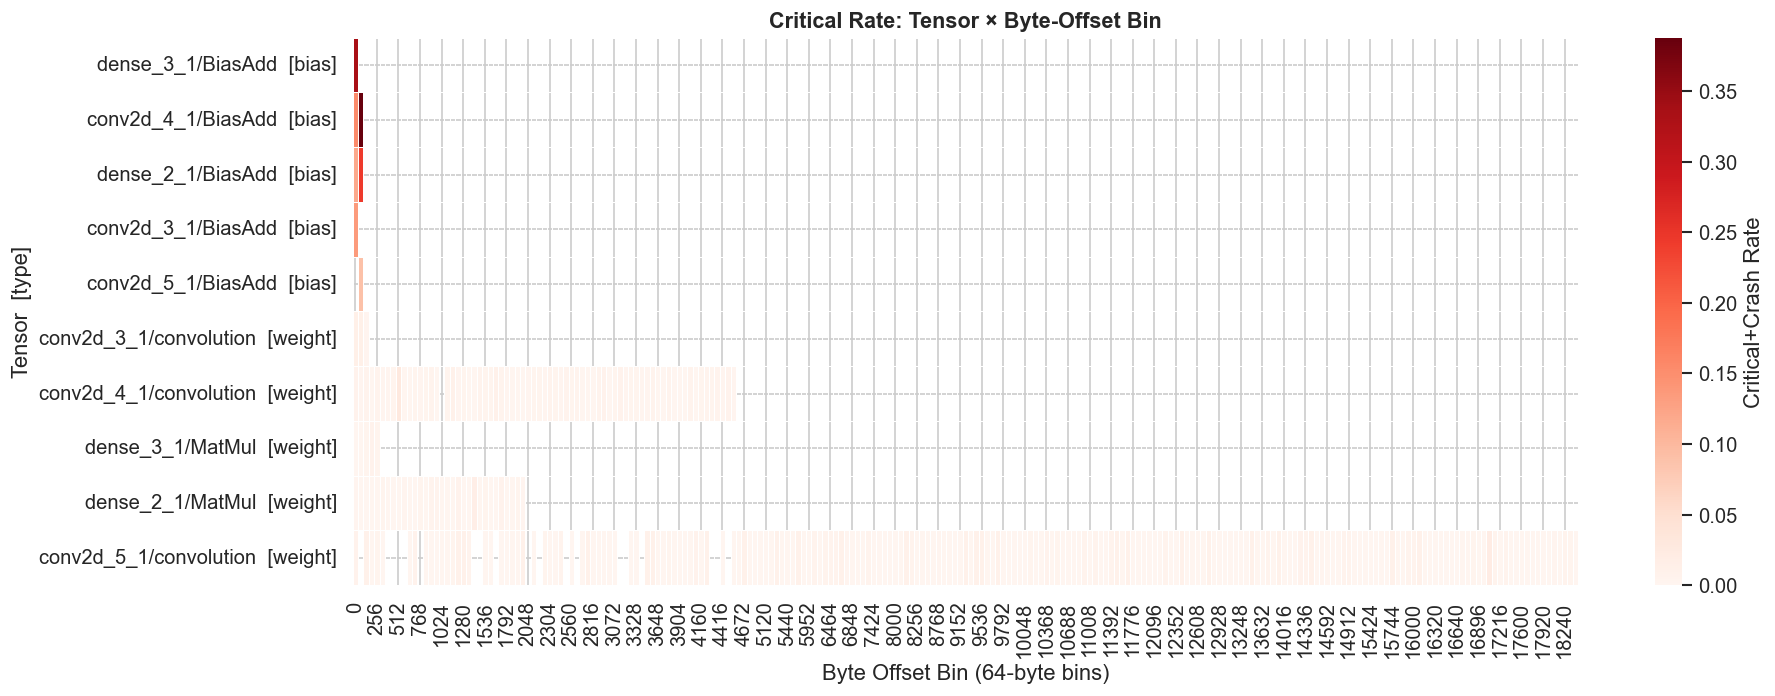

In [ ]:
# Byte-in-tensor bin for heatmap
if "byte_in_tensor" not in df.columns or df["byte_in_tensor"].isna().all():
    if "byte_in_tensor_sel" in df.columns:
        df["byte_in_tensor"] = df["byte_in_tensor_sel"]

# Garante display_label (reaproveita se já foi criado por célula anterior)
if "display_label" not in df.columns:
    def _display_label(name: str) -> str:
        branches = str(name).split(";")
        chosen = next((b for b in branches if "BiasAdd" in b), branches[-1])
        parts = chosen.split("/")
        return "/".join(parts[-2:]) if len(parts) >= 2 else chosen

    _name_by_idx = (
        df.dropna(subset=["tensor_name"])
          .drop_duplicates("tensor_index")
          .set_index("tensor_index")["tensor_name"]
    )
    display_label_map = {idx: _display_label(n) for idx, n in _name_by_idx.items()}
    assert len(set(display_label_map.values())) == len(display_label_map), (
        "Colisão de display_label detectada"
    )
    df["display_label"] = df["tensor_index"].map(display_label_map)

HBIN = 64
df["byte_bin"] = (
    pd.to_numeric(df["byte_in_tensor"], errors="coerce") // HBIN
).astype("Int64") * HBIN

def critical_rate(g):
    return g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0.0

# Agrega por tensor_index (chave física) — evita mismatch com tensor_order
heat_raw = (
    df.dropna(subset=["byte_bin"])
      .groupby(["tensor_index", "byte_bin"])
      .apply(critical_rate)
      .unstack(fill_value=np.nan)
)

# Ordena tensores pela taxa crítica global (descendente)
tensor_order_idx = (
    df.dropna(subset=["byte_bin"])
      .groupby("tensor_index")
      .apply(critical_rate)
      .sort_values(ascending=False)
      .index
)
heat_raw = heat_raw.reindex(tensor_order_idx).dropna(how="all")

# Renomeia índice físico -> label de exibição com tipo
_meta = df.drop_duplicates("tensor_index").set_index("tensor_index")
idx_to_plot_label = (_meta["display_label"] + "  [" + _meta["tensor_type"] + "]").to_dict()
heat_data = heat_raw.rename(index=idx_to_plot_label)

# Diagnóstico — útil se continuar aparecendo vazio
print(f"heat_data: {heat_data.shape[0]} tensores × {heat_data.shape[1]} bins")
if heat_data.empty:
    print("⚠ Nenhum dado após agregação. Verifique:")
    print(f"  - df['byte_in_tensor'] não-nulo? {df['byte_in_tensor'].notna().sum()}")
    print(f"  - tensor_index únicos no df: {df['tensor_index'].nunique()}")
else:
    vmax_eff = float(np.nanmax(heat_data.values))
    print(f"Max critical rate observado: {vmax_eff:.4f}")

    fig, ax = plt.subplots(figsize=(16, max(4, 0.6 * len(heat_data.index))))
    sns.heatmap(
        heat_data,
        cmap="Reds",
        linewidths=0.3,
        linecolor="white",
        ax=ax,
        cbar_kws={"label": "Critical+Crash Rate"},
        vmin=0,
        vmax=max(vmax_eff, 0.01),
    )
    ax.set_title("Critical Rate: Tensor × Byte-Offset Bin",
                 fontweight="bold", fontsize=13)
    ax.set_ylabel("Tensor  [type]")
    ax.set_xlabel(f"Byte Offset Bin ({HBIN}-byte bins)")
    plt.tight_layout()
    plt.savefig(RUN_DIR / "fig_heatmap_tensor_byteoffset.png", bbox_inches="tight")
    plt.show()

## 17. Tensor Size vs Criticality
Examines the relationship between tensor size (in bytes) and its vulnerability to bit-flips. Smaller tensors (biases) may exhibit higher per-byte criticality.

Tensores no scatter: 10


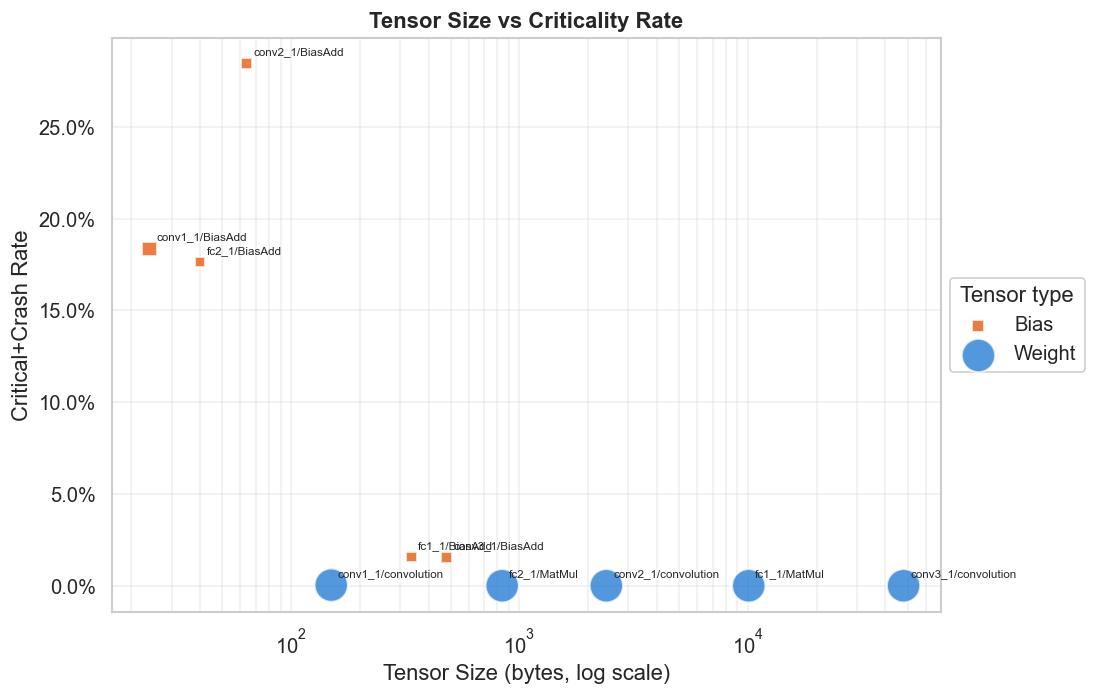

,tensor_index,display_label,tensor_type,tensor_size_bytes,total,critical_rate,degraded_rate
0,10.0,conv2_1/BiasAdd,bias,64,700.0,0.2843,0.3143
1,12.0,conv1_1/BiasAdd,bias,24,3600.0,0.1836,0.2511
2,4.0,fc2_1/BiasAdd,bias,40,1600.0,0.1762,0.1944
3,6.0,fc1_1/BiasAdd,bias,336,1600.0,0.0156,0.0688
4,8.0,conv3_1/BiasAdd,bias,480,393.0,0.0153,0.0356
5,13.0,conv1_1/convolution,weight,150,26600.0,0.0003,0.0076
6,5.0,fc2_1/MatMul,weight,840,34900.0,0.0000,0.0007
7,7.0,fc1_1/MatMul,weight,10080,36700.0,0.0000,0.0004
8,9.0,conv3_1/convolution,weight,48000,38000.0,0.0000,0.0006
9,11.0,conv2_1/convolution,weight,2400,37000.0,0.0000,0.0040


In [24]:
# Garante artefatos das células anteriores (reaproveita se já existirem)
def _display_label(name: str) -> str:
    branches = str(name).split(";")
    chosen = next((b for b in branches if "BiasAdd" in b), branches[-1])
    parts = chosen.split("/")
    return "/".join(parts[-2:]) if len(parts) >= 2 else chosen

def _classify_tensor(name: str) -> str:
    n = str(name).lower()
    if "bias" in n:
        return "bias"
    if any(k in n for k in ("reduction_indices", "/axis", "/perm", "/shape")):
        return "hyperparam"
    if any(k in n for k in ("matmul", "convolution", "kernel", "depthwise", "filter")):
        return "weight"
    return "other"

if "display_label" not in df.columns:
    _name_by_idx = (
        df.dropna(subset=["tensor_name"])
          .drop_duplicates("tensor_index")
          .set_index("tensor_index")["tensor_name"]
    )
    display_label_map = {idx: _display_label(n) for idx, n in _name_by_idx.items()}
    assert len(set(display_label_map.values())) == len(display_label_map)
    df["display_label"] = df["tensor_index"].map(display_label_map)

def critical_rate(g):
    return g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0.0

def degraded_rate(g):
    return g["fault_class"].isin(DEGRADED_SET).sum() / len(g) if len(g) > 0 else 0.0

# --- Tensor-level summary agregado por tensor_index (chave física) ----------
tensor_summary = (
    df.groupby("tensor_index")
      .apply(lambda g: pd.Series({
          "total": len(g),
          "critical_rate": critical_rate(g),
          "degraded_rate": degraded_rate(g),
      }))
)

# Tamanho vem diretamente do tensor_map por tensor_index (chave única, sem colisão)
size_by_idx = tensor_map.set_index("tensor_index")["length_bytes"].to_dict()
tensor_summary["tensor_size_bytes"] = tensor_summary.index.map(size_by_idx)

# Tipo via _classify_tensor (3 categorias, não binário enganoso)
name_by_idx = tensor_map.set_index("tensor_index")["name"].to_dict()
tensor_summary["tensor_type"] = tensor_summary.index.map(
    {idx: _classify_tensor(n) for idx, n in name_by_idx.items()}
)

# Display label único por tensor
label_by_idx = {idx: _display_label(n) for idx, n in name_by_idx.items()}
tensor_summary["display_label"] = tensor_summary.index.map(label_by_idx)

# Filtra apenas tensores efetivamente injetados e com tamanho conhecido
tensor_summary = tensor_summary.dropna(subset=["tensor_size_bytes"])
tensor_summary = tensor_summary[tensor_summary["total"] > 0]
tensor_summary["tensor_size_bytes"] = tensor_summary["tensor_size_bytes"].astype(int)

print(f"Tensores no scatter: {len(tensor_summary)}")
if tensor_summary.empty:
    print("⚠ Sem dados para plotar. Verifique se o df tem tensor_index válido.")
else:
    # --- Scatter ------------------------------------------------------------
    type_colors = {"weight": "#1976D2", "bias": "#E65100",
                   "hyperparam": "#757575", "other": "#9E9E9E"}
    type_markers = {"weight": "o", "bias": "s",
                    "hyperparam": "^", "other": "x"}

    fig, ax = plt.subplots(figsize=(11, 6))
    for tt, sub in tensor_summary.groupby("tensor_type"):
        ax.scatter(
            sub["tensor_size_bytes"], sub["critical_rate"],
            s=np.clip(sub["total"] / 50, 40, 400),
            alpha=0.75,
            label=tt.title(),
            color=type_colors.get(tt, "#666"),
            marker=type_markers.get(tt, "o"),
            edgecolors="white", linewidths=1.2,
        )
        for idx, row in sub.iterrows():
            ax.annotate(
                row["display_label"],
                (row["tensor_size_bytes"], row["critical_rate"]),
                fontsize=7, ha="left", va="bottom",
                xytext=(4, 4), textcoords="offset points",
            )

    ax.set_xscale("log")
    ax.set_xlabel("Tensor Size (bytes, log scale)")
    ax.set_ylabel("Critical+Crash Rate")
    ax.set_title("Tensor Size vs Criticality Rate", fontweight="bold")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.grid(True, which="both", alpha=0.3)

    ax.legend(
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        title="Tensor type",
        framealpha=0.95,
        borderaxespad=0.0,
    )

    plt.tight_layout(rect=[0, 0, 0.85, 1])
    plt.savefig(RUN_DIR / "fig_tensor_size_vs_criticality.png", bbox_inches="tight")
    plt.show()

    display(
        tensor_summary[["display_label", "tensor_type", "tensor_size_bytes",
                        "total", "critical_rate", "degraded_rate"]]
        .sort_values("critical_rate", ascending=False)
        .round(4)
        .reset_index()
        .rename(columns={"index": "tensor_index"})
    )

## 18. Confusion Matrix Under Fault
How faults redistribute predictions across classes — aggregated over all critical faults.

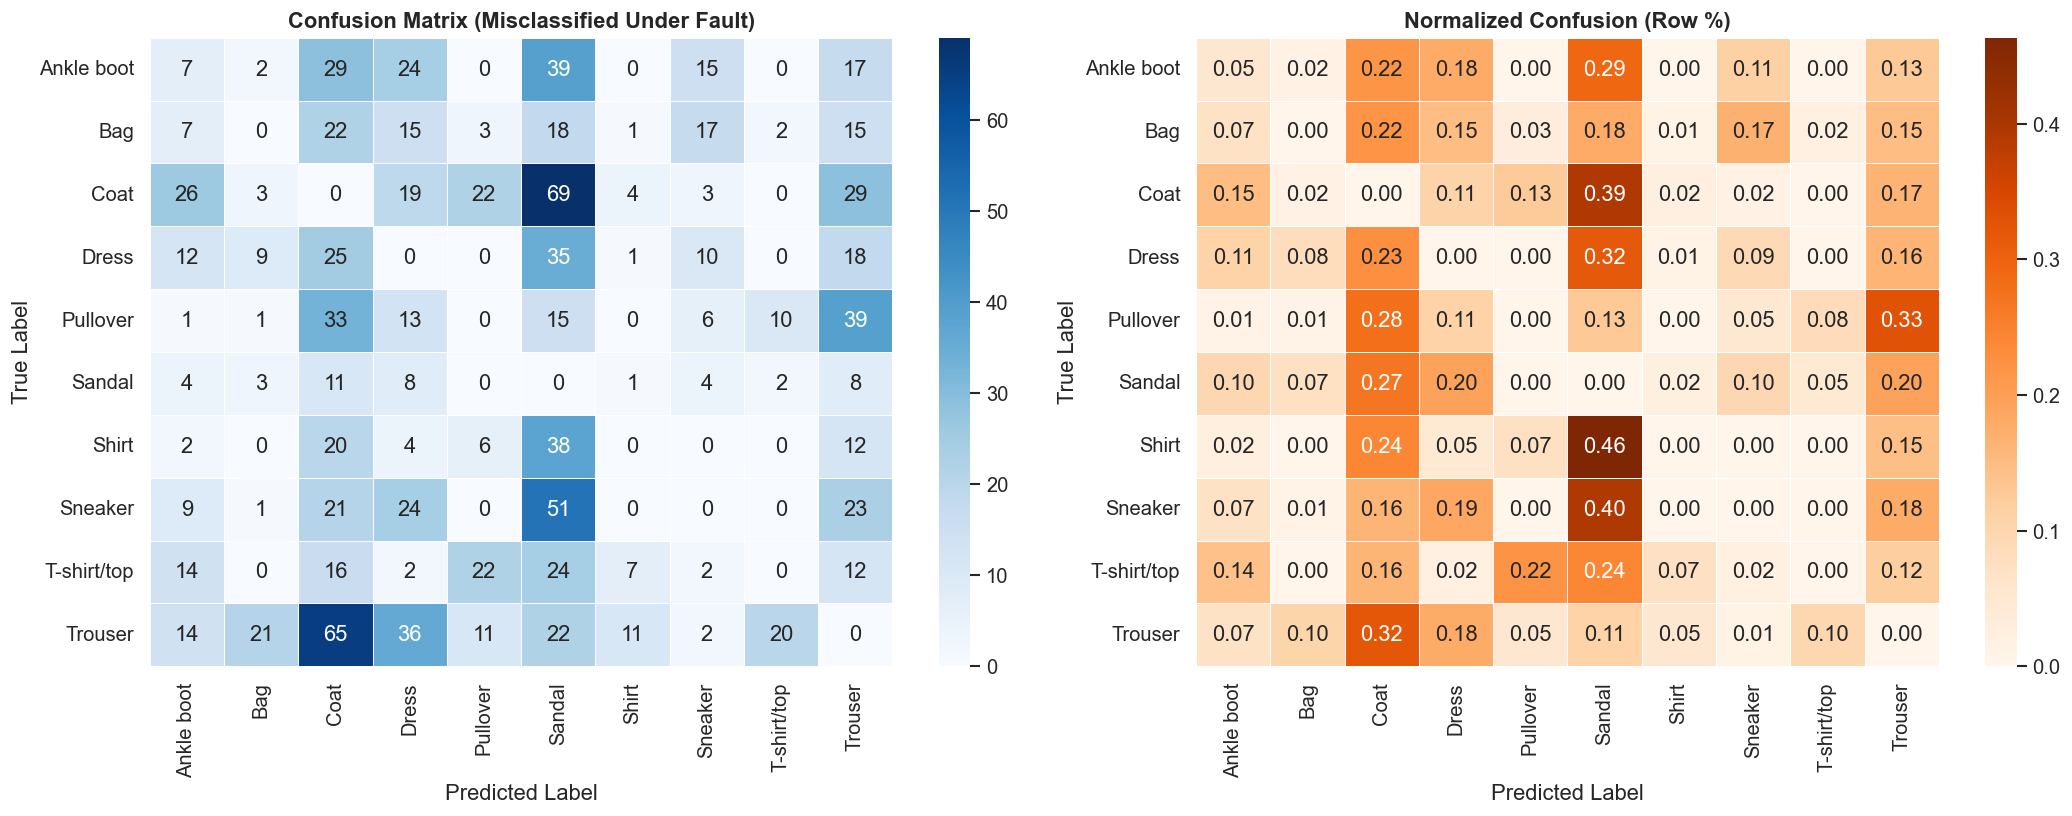

In [25]:
FASHION_LABELS = {
    0: "T-shirt/top", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
    5: "Sandal", 6: "Shirt", 7: "Sneaker", 8: "Bag", 9: "Ankle boot"
}

# Only misclassified under fault (not masked)
mis_df = df[df["pred_class"] != df["golden_pred_class_ref"]].copy()
mis_df["true_label"] = mis_df["label"].map(FASHION_LABELS)
mis_df["pred_label"] = mis_df["pred_class"].map(FASHION_LABELS)

cm = pd.crosstab(mis_df["true_label"], mis_df["pred_label"], margins=False)
# Normalize by row
cm_norm = cm.div(cm.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            linewidths=0.5, linecolor="white")
axes[0].set_title("Confusion Matrix (Misclassified Under Fault)", fontweight="bold")
axes[0].set_ylabel("True Label")
axes[0].set_xlabel("Predicted Label")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Oranges", ax=axes[1],
            linewidths=0.5, linecolor="white")
axes[1].set_title("Normalized Confusion (Row %)", fontweight="bold")
axes[1].set_ylabel("True Label")
axes[1].set_xlabel("Predicted Label")

plt.tight_layout()
plt.savefig(RUN_DIR / "fig_confusion_under_fault.png", bbox_inches="tight")
plt.show()

## 19. Summary Tables for Paper

In [27]:
# --- Helpers ----------------------------------------------------------------
def _pct(series) -> pd.Series:
    """Converte fração em string percentual, preservando NaN como '—'."""
    return series.apply(
        lambda v: f"{v*100:.2f}%" if pd.notna(v) else "—"
    )

def _display_label(name: str) -> str:
    branches = str(name).split(";")
    chosen = next((b for b in branches if "BiasAdd" in b), branches[-1])
    parts = chosen.split("/")
    return "/".join(parts[-2:]) if len(parts) >= 2 else chosen

def _classify_tensor(name: str) -> str:
    n = str(name).lower()
    if "bias" in n:
        return "bias"
    if any(k in n for k in ("reduction_indices", "/axis", "/perm", "/shape")):
        return "hyperparam"
    if any(k in n for k in ("matmul", "convolution", "kernel", "depthwise", "filter")):
        return "weight"
    return "other"

def _critical_rate(g):
    return g["fault_class"].isin(CRITICAL_SET).sum() / len(g) if len(g) > 0 else 0.0

def _degraded_rate(g):
    return g["fault_class"].isin(DEGRADED_SET).sum() / len(g) if len(g) > 0 else 0.0

# Guarda: reconstrói display_label se célula rodar isolada
if "display_label" not in df.columns:
    _name_by_idx = (
        df.dropna(subset=["tensor_name"])
          .drop_duplicates("tensor_index")
          .set_index("tensor_index")["tensor_name"]
    )
    display_label_map = {idx: _display_label(n) for idx, n in _name_by_idx.items()}
    df["display_label"] = df["tensor_index"].map(display_label_map)

if "tensor_type" not in df.columns:
    _name_by_idx = tensor_map.set_index("tensor_index")["name"].to_dict()
    df["tensor_type"] = df["tensor_index"].map(
        {idx: _classify_tensor(n) for idx, n in _name_by_idx.items()}
    )

# Métricas globais (caso as variáveis de células anteriores não existam)
if "golden_acc" not in globals():
    golden_acc = (df["golden_pred_class_ref"] == df["label"]).sum() / len(df)
if "faulty_acc" not in globals():
    faulty_acc = (df["pred_class"] == df["label"]).sum() / len(df)

SEVERITY_COLS = [c for c in SEVERITY_ORDER if c in df["fault_class"].unique()]

# --- Cabeçalho --------------------------------------------------------------
print("=" * 70)
print("  SUMMARY — Memory Fault Injection Campaign")
print("=" * 70)
print(f"  Model           : LeNet-5 INT8 TFLite")
print(f"  Fault model     : {manifest.get('campaign_type', 'memory')}")
print(f"  Fault duration  : {manifest.get('fault_duration', 'transient')}")
print(f"  Total inferences: {len(df):,}")
print(f"  Unique faults   : {df['fault_id'].nunique():,}")
print(f"  Images/fault    : {len(df) // max(df['fault_id'].nunique(), 1)}")
print(f"  Operators       : {df['operator_index'].nunique()}")
print(f"  Tensors         : {df['tensor_index'].nunique()}")
print(f"  Golden accuracy : {golden_acc:.4f}")
print(f"  Faulty accuracy : {faulty_acc:.4f}")
print(f"  Accuracy drop   : {(golden_acc - faulty_acc)*100:.2f} pp")
print("=" * 70)

# --- Table 1: Overall classification ----------------------------------------
print("\n--- Table 1: Overall Fault Classification ---")
if "summary_table" in globals():
    display(summary_table)
else:
    counts = df["fault_class"].value_counts().reindex(SEVERITY_COLS, fill_value=0)
    summary_table = pd.DataFrame({
        "count": counts,
        "pct": _pct(counts / counts.sum()),
    })
    display(summary_table)

# --- Table 2: Criticality by Tensor Type ------------------------------------
print("\n--- Table 2: Criticality by Tensor Type ---")
ttype_fc2 = (
    df.groupby("tensor_type")["fault_class"]
      .value_counts().unstack(fill_value=0)
      .reindex(columns=SEVERITY_ORDER, fill_value=0)
)
ttype_fc2["total"] = ttype_fc2[SEVERITY_ORDER].sum(axis=1)
ttype_fc2["critical_rate"] = (
    ttype_fc2.get("Critical", 0) + ttype_fc2.get("Crash", 0)
) / ttype_fc2["total"].replace(0, np.nan)
ttype_fc2["degraded_rate"] = ttype_fc2[
    [c for c in DEGRADED_SET if c in ttype_fc2.columns]
].sum(axis=1) / ttype_fc2["total"].replace(0, np.nan)

ttype_paper = ttype_fc2[["total"] + SEVERITY_COLS +
                        ["critical_rate", "degraded_rate"]].copy()
ttype_paper["critical_rate"] = _pct(ttype_paper["critical_rate"])
ttype_paper["degraded_rate"] = _pct(ttype_paper["degraded_rate"])
display(ttype_paper)

# --- Table 3: Criticality by Operator Instance ------------------------------
print("\n--- Table 3: Criticality by Operator Instance ---")
if "op_fc" in globals():
    base_cols = [c for c in ["total"] + SEVERITY_COLS +
                 ["critical_rate", "degraded_rate"] if c in op_fc.columns]
    op_paper = op_fc[base_cols].copy()
    if "critical_rate" in op_paper.columns:
        op_paper["critical_rate"] = _pct(op_paper["critical_rate"])
    if "degraded_rate" in op_paper.columns:
        op_paper["degraded_rate"] = _pct(op_paper["degraded_rate"])
    display(op_paper)
else:
    print("  ⚠ op_fc não está definido — rode a célula de análise por operador antes.")

# --- Table 4: Criticality by Tensor -----------------------------------------
print("\n--- Table 4: Criticality by Tensor ---")
# Reconstrói a partir de tensor_index (chave física) para ficar independente
# da forma exata como tensor_fc foi montado em células anteriores.
tensor_fc2 = (
    df.groupby(["tensor_index", "display_label", "tensor_type"])["fault_class"]
      .value_counts().unstack(fill_value=0)
      .reindex(columns=SEVERITY_ORDER, fill_value=0)
)
tensor_fc2["total"] = tensor_fc2[SEVERITY_ORDER].sum(axis=1)
tensor_fc2["critical_rate"] = (
    tensor_fc2.get("Critical", 0) + tensor_fc2.get("Crash", 0)
) / tensor_fc2["total"].replace(0, np.nan)
tensor_fc2["degraded_rate"] = tensor_fc2[
    [c for c in DEGRADED_SET if c in tensor_fc2.columns]
].sum(axis=1) / tensor_fc2["total"].replace(0, np.nan)
tensor_fc2 = tensor_fc2.sort_values("critical_rate", ascending=False)

# Achata MultiIndex para apresentação: display_label [type]
tensor_paper = tensor_fc2.reset_index()
tensor_paper["tensor"] = (
    tensor_paper["display_label"] + "  [" + tensor_paper["tensor_type"] + "]"
)
tensor_paper = tensor_paper.set_index("tensor")[
    ["tensor_index", "total"] + SEVERITY_COLS +
    ["critical_rate", "degraded_rate"]
].copy()
tensor_paper["critical_rate"] = _pct(tensor_paper["critical_rate"])
tensor_paper["degraded_rate"] = _pct(tensor_paper["degraded_rate"])
display(tensor_paper)

# --- Table 5: Bit-Position Vulnerability ------------------------------------
print("\n--- Table 5: Bit-Position Vulnerability ---")
# Reconstrói de forma robusta a partir de df (source of truth)
bit_fc2 = (
    df.groupby("bit_index")
      .apply(lambda g: pd.Series({
          "total": len(g),
          "critical": g["fault_class"].isin(CRITICAL_SET).sum(),
          "masked": (g["fault_class"] == "Masked").sum(),
          "critical_rate": _critical_rate(g),
          "masked_rate": (g["fault_class"] == "Masked").sum() / len(g),
      }))
      .reset_index()
      .sort_values("bit_index")
)
bit_paper = bit_fc2[["bit_index", "total", "critical",
                     "critical_rate", "masked_rate"]].copy()
bit_paper["bit_index"] = bit_paper["bit_index"].astype(int)
bit_paper["critical_rate"] = _pct(bit_paper["critical_rate"])
bit_paper["masked_rate"]   = _pct(bit_paper["masked_rate"])
display(bit_paper.reset_index(drop=True))

  SUMMARY — Memory Fault Injection Campaign
  Model           : LeNet-5 INT8 TFLite
  Fault model     : memory
  Fault duration  : transient
  Total inferences: 181,093
  Unique faults   : 1,811
  Images/fault    : 99
  Operators       : 5
  Tensors         : 10
  Golden accuracy : 0.9900
  Faulty accuracy : 0.9836
  Accuracy drop   : 0.64 pp

--- Table 1: Overall Fault Classification ---


,Count,Percentage (%)
fault_class,,
Masked,176219.0,97.31
Good,7.0,0.00
Acceptable,2897.0,1.60
Warning,788.0,0.44
Critical,1182.0,0.65
TOTAL,181093.0,100.00



--- Table 2: Criticality by Tensor Type ---


fault_class,total,Masked,Good,Acceptable,Warning,Critical,critical_rate,degraded_rate
tensor_type,,,,,,,,
bias,7893,5805,7,522,386,1173,14.86%,19.75%
weight,173200,170414,0,2375,402,9,0.01%,0.24%



--- Table 3: Criticality by Operator Instance ---


fault_class,total,Masked,Good,Acceptable,Warning,Critical,critical_rate,degraded_rate
op_label,,,,,,,,
0_CONV_2D,30200,27716,1,1378,435,670,2.22%,3.66%
2_CONV_2D,37700,36516,0,815,170,199,0.53%,0.98%
4_CONV_2D,38393,38210,0,148,29,6,0.02%,0.09%
9_FULLY_CONNECTED,38300,37922,5,247,101,25,0.07%,0.33%
10_FULLY_CONNECTED,36500,35855,1,309,53,282,0.77%,0.92%



--- Table 4: Criticality by Tensor ---


fault_class,tensor_index,total,Masked,Good,Acceptable,Warning,Critical,critical_rate,degraded_rate
tensor,,,,,,,,,
conv2_1/BiasAdd [bias],10.0,700,443,0,37,21,199,28.43%,31.43%
conv1_1/BiasAdd [bias],12.0,3600,2413,1,282,243,661,18.36%,25.11%
fc2_1/BiasAdd [bias],4.0,1600,1249,1,39,29,282,17.62%,19.44%
fc1_1/BiasAdd [bias],6.0,1600,1346,5,139,85,25,1.56%,6.88%
conv3_1/BiasAdd [bias],8.0,393,354,0,25,8,6,1.53%,3.56%
conv1_1/convolution [weight],13.0,26600,25303,0,1096,192,9,0.03%,0.76%
fc2_1/MatMul [weight],5.0,34900,34606,0,270,24,0,0.00%,0.07%
fc1_1/MatMul [weight],7.0,36700,36576,0,108,16,0,0.00%,0.04%
conv3_1/convolution [weight],9.0,38000,37856,0,123,21,0,0.00%,0.06%



--- Table 5: Bit-Position Vulnerability ---


,bit_index,total,critical,critical_rate,masked_rate
0,0,22900.0,95.0,0.41%,98.47%
1,1,25100.0,86.0,0.34%,98.64%
2,2,22900.0,283.0,1.24%,96.99%
3,3,19400.0,125.0,0.64%,97.68%
4,4,20700.0,148.0,0.71%,97.71%
5,5,23993.0,150.0,0.63%,97.28%
6,6,21700.0,21.0,0.10%,97.13%
7,7,24400.0,274.0,1.12%,94.70%


## 20. Export LaTeX-ready Tables

In [ ]:
EXPORT_DIR = RUN_DIR / "paper_exports"
EXPORT_DIR.mkdir(exist_ok=True)

# --- Helpers ----------------------------------------------------------------
def _present_sev_cols(frame: pd.DataFrame) -> list:
    """Retorna apenas severidades presentes em `frame`, na ordem canônica."""
    return [c for c in SEVERITY_ORDER if c in frame.columns]

def _safe_export(name: str, func):
    """Executa `func()` e captura exceções para não abortar o resto."""
    try:
        func()
        print(f"  ✓ {name}")
    except Exception as e:
        print(f"  ✗ {name}  ({type(e).__name__}: {e})")

def _write_csv(df_or_series, path: Path, **kwargs):
    df_or_series.to_csv(path, **kwargs)

def _write_latex(df: pd.DataFrame, path: Path, **kwargs):
    # to_latex com float_format padrão e escape=False para caracteres especiais
    kwargs.setdefault("float_format", "%.4f")
    kwargs.setdefault("escape", True)
    with open(path, "w", encoding="utf-8") as f:
        f.write(df.to_latex(**kwargs))

# --- Sanity: força variáveis opcionais a existirem --------------------------
# (evita NameError; cada export é tentado independentemente)
_globals = globals()

print(f"Exportando para: {EXPORT_DIR.resolve()}")
print("\n[CSV]")

# Table 1: Overall classification
if "summary_table" in _globals:
    _safe_export(
        "table_overall_classification.csv",
        lambda: _write_csv(summary_table, EXPORT_DIR / "table_overall_classification.csv"),
    )

# Table 2: By tensor type
if "ttype_fc" in _globals:
    _safe_export(
        "table_tensor_type.csv",
        lambda: _write_csv(
            ttype_fc[
                ["total"] + _present_sev_cols(ttype_fc) +
                [c for c in ("critical_rate", "degraded_rate") if c in ttype_fc.columns]
            ].round(4),
            EXPORT_DIR / "table_tensor_type.csv",
        ),
    )

# Table 3: By operator instance
if "op_fc" in _globals:
    _op_cols = (
        ["total"] + _present_sev_cols(op_fc) +
        [c for c in ("critical_rate", "degraded_rate") if c in op_fc.columns]
    )
    _safe_export(
        "table_operator_instance.csv",
        lambda: _write_csv(op_fc[_op_cols].round(4),
                           EXPORT_DIR / "table_operator_instance.csv"),
    )

# Table 4: By tensor — achata MultiIndex se houver
if "tensor_fc" in _globals:
    _tensor_fc_flat = tensor_fc.copy()
    if isinstance(_tensor_fc_flat.index, pd.MultiIndex):
        _tensor_fc_flat = _tensor_fc_flat.reset_index()
    _t_cols = (
        [c for c in ("tensor_index", "display_label", "tensor_type")
         if c in _tensor_fc_flat.columns] +
        ["total"] + _present_sev_cols(_tensor_fc_flat) +
        [c for c in ("critical_rate", "degraded_rate")
         if c in _tensor_fc_flat.columns]
    )
    _safe_export(
        "table_tensor.csv",
        lambda: _write_csv(
            _tensor_fc_flat[_t_cols].round(4),
            EXPORT_DIR / "table_tensor.csv",
            index=not isinstance(tensor_fc.index, pd.MultiIndex),
        ),
    )

# Table 5: Bit vulnerability
if "bit_fc" in _globals:
    _safe_export(
        "table_bit_vulnerability.csv",
        lambda: _write_csv(
            (bit_fc.reset_index() if "bit_index" not in bit_fc.columns else bit_fc).round(4),
            EXPORT_DIR / "table_bit_vulnerability.csv",
            index=False,
        ),
    )

# Confidence intervals
if "ci_df" in _globals:
    _safe_export(
        "table_ci_per_tensor.csv",
        lambda: _write_csv(ci_df.round(4),
                           EXPORT_DIR / "table_ci_per_tensor.csv",
                           index=False),
    )
else:
    print("  – table_ci_per_tensor.csv (ci_df não definido, pulando)")

# Accuracy per tensor
if "acc_per_tensor" in _globals:
    _safe_export(
        "table_accuracy_per_tensor.csv",
        lambda: _write_csv(acc_per_tensor.round(4),
                           EXPORT_DIR / "table_accuracy_per_tensor.csv"),
    )
else:
    print("  – table_accuracy_per_tensor.csv (acc_per_tensor não definido, pulando)")

# Accuracy per operator
if "acc_per_op" in _globals:
    _safe_export(
        "table_accuracy_per_operator.csv",
        lambda: _write_csv(acc_per_op.round(4),
                           EXPORT_DIR / "table_accuracy_per_operator.csv"),
    )
else:
    print("  – table_accuracy_per_operator.csv (acc_per_op não definido, pulando)")

# --- LaTeX exports ----------------------------------------------------------
print("\n[LaTeX]")

if "summary_table" in _globals:
    # Para LaTeX, precisamos de dados numéricos; se summary_table já foi formatado
    # com strings "%", usamos versão bruta calculada de df.
    try:
        _sum_numeric = summary_table.copy()
        # Se alguma coluna tem strings, reconstrói do df
        if _sum_numeric.select_dtypes(include="object").shape[1] > 0:
            _counts = df["fault_class"].value_counts().reindex(
                _present_sev_cols(df.to_frame().rename(columns={0: "fault_class"})
                                  if isinstance(df, pd.Series) else df),
                fill_value=0,
            )
            # Fallback simples
            _counts = df["fault_class"].value_counts()
            _counts = _counts.reindex([c for c in SEVERITY_ORDER if c in _counts.index],
                                      fill_value=0)
            _sum_numeric = pd.DataFrame({
                "count": _counts,
                "pct": (_counts / _counts.sum()).round(4),
            })
        _safe_export(
            "latex_overall_classification.tex",
            lambda: _write_latex(_sum_numeric,
                                 EXPORT_DIR / "latex_overall_classification.tex",
                                 float_format="%.4f"),
        )
    except Exception as e:
        print(f"  ✗ latex_overall_classification.tex ({type(e).__name__}: {e})")

if "ttype_fc" in _globals:
    _cols = [c for c in ("total", "critical_rate", "degraded_rate")
             if c in ttype_fc.columns]
    _safe_export(
        "latex_tensor_type.tex",
        lambda: _write_latex(ttype_fc[_cols].round(4),
                             EXPORT_DIR / "latex_tensor_type.tex"),
    )

if "op_fc" in _globals:
    _cols = [c for c in ("total", "critical_rate", "degraded_rate")
             if c in op_fc.columns]
    _safe_export(
        "latex_operator_instance.tex",
        lambda: _write_latex(op_fc[_cols].round(4),
                             EXPORT_DIR / "latex_operator_instance.tex"),
    )

if "tensor_fc" in _globals:
    _tflat = tensor_fc.copy()
    if isinstance(_tflat.index, pd.MultiIndex):
        _tflat = _tflat.reset_index()
        # usa display_label como índice no LaTeX, se disponível
        if "display_label" in _tflat.columns and "tensor_type" in _tflat.columns:
            _tflat["tensor"] = _tflat["display_label"] + " [" + _tflat["tensor_type"] + "]"
            _tflat = _tflat.set_index("tensor")
    _cols = [c for c in ("total", "critical_rate", "degraded_rate")
             if c in _tflat.columns]
    _safe_export(
        "latex_tensor.tex",
        lambda: _write_latex(_tflat[_cols].round(4),
                             EXPORT_DIR / "latex_tensor.tex"),
    )

# --- Listagem final ---------------------------------------------------------
print(f"\nExports salvos em: {EXPORT_DIR.resolve()}")
print("Arquivos gerados:")
for p in sorted(EXPORT_DIR.iterdir()):
    size_kb = p.stat().st_size / 1024
    print(f"  - {p.name}  ({size_kb:.1f} KB)")

Exportando para: C:\Downloads\framework_jose\analysis_runs\Memoria_transient\memoryfi_image_classification_20260417_092811\paper_exports

[CSV]
  ✓ table_overall_classification.csv
  ✓ table_tensor_type.csv
  ✓ table_operator_instance.csv
  ✓ table_tensor.csv
  ✓ table_bit_vulnerability.csv
  ✓ table_ci_per_tensor.csv
  ✓ table_accuracy_per_tensor.csv
  ✓ table_accuracy_per_operator.csv

[LaTeX]
  ✗ latex_overall_classification.tex  (ImportError: `Import Jinja2` failed. DataFrame.style requires jinja2. Use pip or conda to install the Jinja2 package.)
  ✗ latex_tensor_type.tex  (ImportError: `Import Jinja2` failed. DataFrame.style requires jinja2. Use pip or conda to install the Jinja2 package.)
  ✗ latex_operator_instance.tex  (ImportError: `Import Jinja2` failed. DataFrame.style requires jinja2. Use pip or conda to install the Jinja2 package.)
  ✗ latex_tensor.tex  (ImportError: `Import Jinja2` failed. DataFrame.style requires jinja2. Use pip or conda to install the Jinja2 package.)

